Assumed dependencies: m0 * h, (h-d)/radwidth, h/(h-d), (h-d1)/(h-d2).

Two steps:
1. Fix these, generate a lot of data, see how the histograms look (seek hints at other dependencies).
2. Fix three and vary 1 (m0h, h-d/radwidth), or fix two and vary two (the two height ratios) to see what happens and what dependencies might be.

In [1]:
import sys
from pathlib import Path
HERE = Path.cwd().resolve()
up2_path = str((HERE / ".." / "..").resolve())
up3_path = str((HERE / ".." / ".." / "..").resolve())
for pathstr in [up2_path, up3_path]:
  if pathstr not in sys.path:
      sys.path.insert(0, pathstr)

from helpers import *
import numpy as np
from numpy import random

import matplotlib.pyplot as plt
file1 = str((HERE / "data" / "histogram-1.pkl").resolve())

In [2]:
def populate_hist_vals(m0h, hmdr, left_ratio, right_ratio):
  hmd2 = random.uniform(low = 1., high = 50.)
  hmd1 = left_ratio * hmd2
  h = right_ratio * hmd2
  m0 = m0h/h
  radwidth2 = hmd2/hmdr
  hmd0 = random.uniform(low = 0., high = h)
  radwidth0 = hmd0/random.uniform(low = 1., high = 3.)
  radwidth1 = hmd1/random.uniform(low = 1., high = 3.)
  hmds = [hmd0, hmd1, hmd2]
  radwidths = [radwidth0, radwidth1, radwidth2]
  d = [h - hmds[i] for i in range(3)]
  a = [sum(radwidths[:i + 1]) for i in range(3)]
  return h, d, a, m0

def swap_vals(prob, d, a):
  # Avoids mk recomputations.
  prob.d = d
  prob.a = a
  prob.scale = a
  return prob

In [3]:
# Generate file1 histogram data.

hist_m0hs = [10, 40]
hist_hmdrs = [2, 20]
hist_lratios = [0.4, 0.99, 1.3]
hist_rratios = [1.4, 2, 6]

quads = [(m0h, hmdr, lratio, rratio) for m0h in hist_m0hs for hmdr in hist_hmdrs
          for lratio in hist_lratios for rratio in hist_rratios]

big_nmk = 200
nmk_max = 150
NMK = [big_nmk] * 4
heaving = [0, 0, 1]
rho = 1023

# fixed_prob_lsts = []

# for quad in quads:
#   fixed_prob_lst = []
#   for j in range(50):
#     h, d, a, m0 =  populate_hist_vals(quad[0], quad[1], quad[2], quad[3])
#     prob = ConvergenceProblemI(h, d, a, heaving, NMK, m0, rho)
#     mk = prob.m_k
#     info = {"h" : h,
#             "d" : d,
#             "a" : a,
#             "region" : 2,
#             "m0s" : [m0]}
#     print(j, info)
#     data_dict = merge_dicts(info, prob.convergence_study_over_m0s(nmk_max, [m0], [mk]))
#     fixed_prob_lst.append(data_dict)
#   fixed_prob_lsts.append(fixed_prob_lst)
#   update_data_file(fixed_prob_lsts, file1)
#   print("Finished a quad.")

fixed_prob_lsts = open_pkl_file(file1)
for fixed_prob_lst in fixed_prob_lsts:
  generate_convergence_data(fixed_prob_lst, [0.01, 0.005])

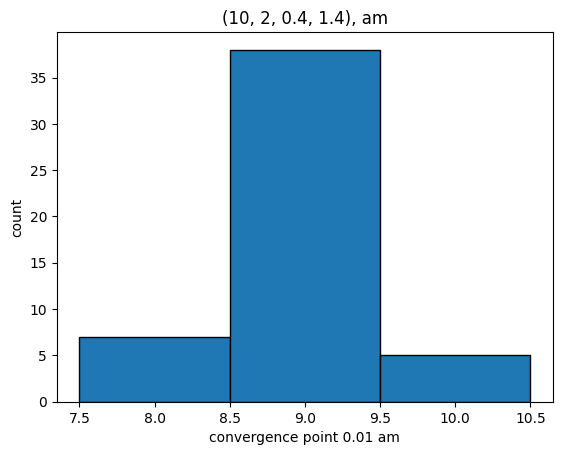

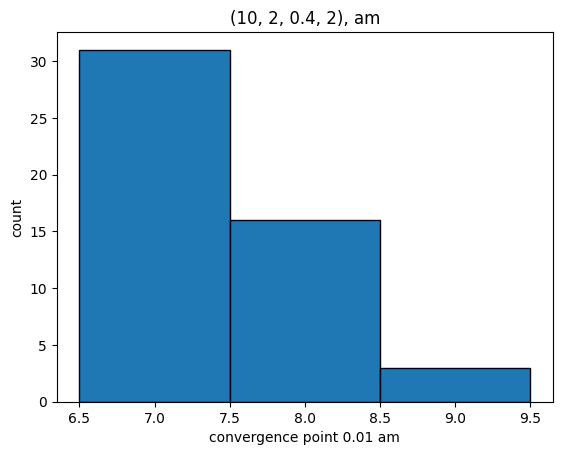

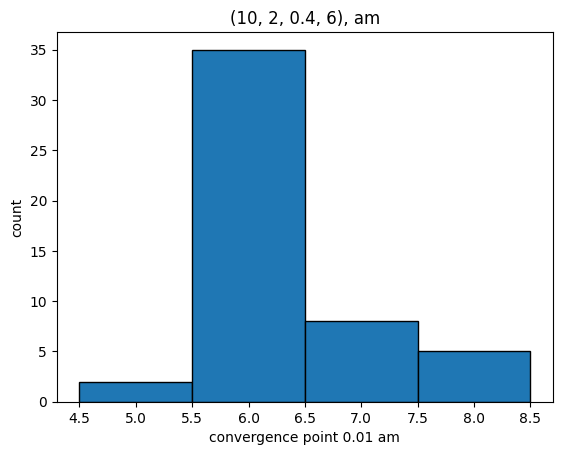

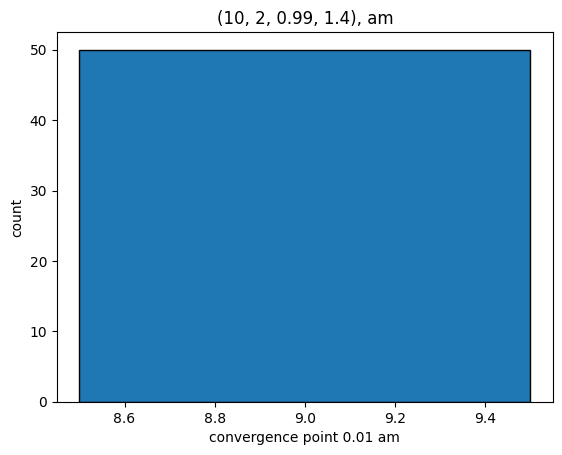

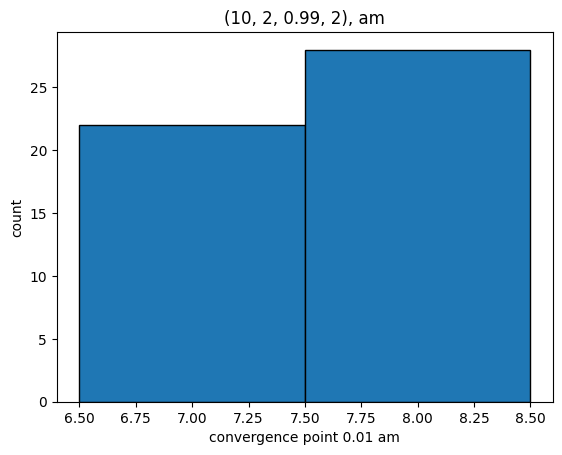

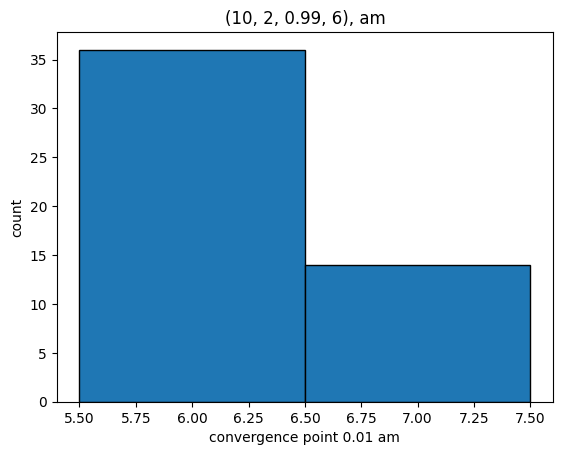

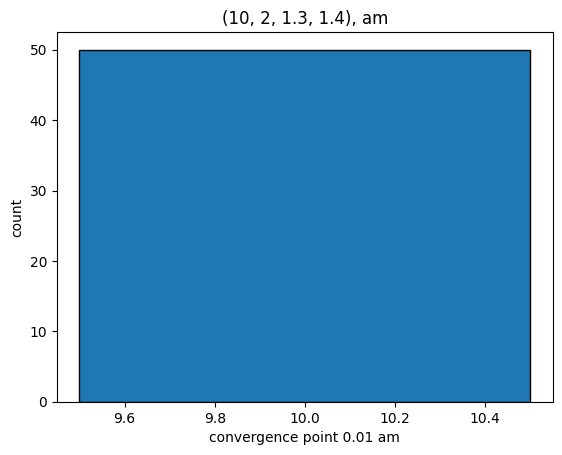

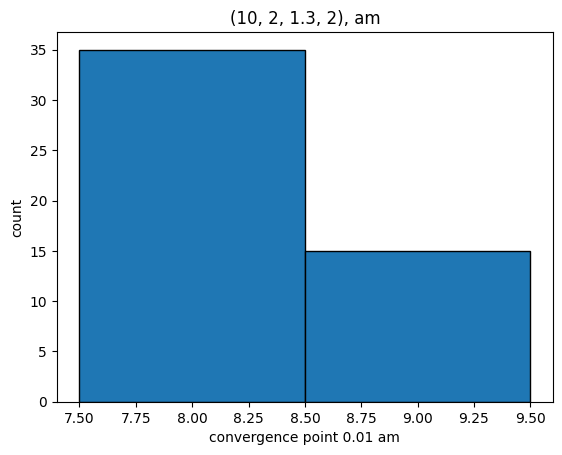

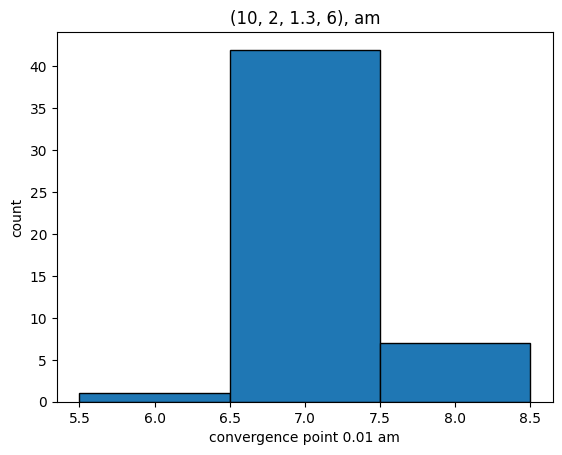

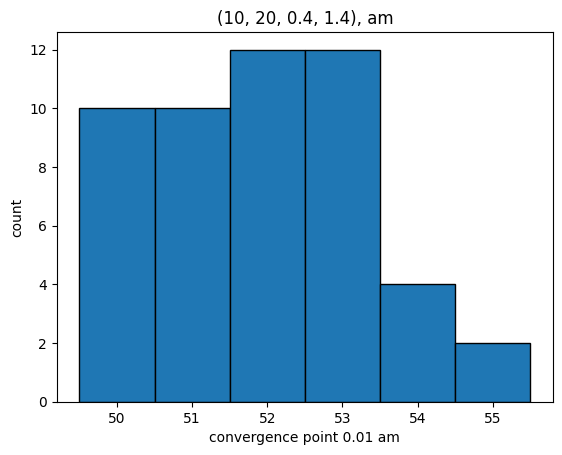

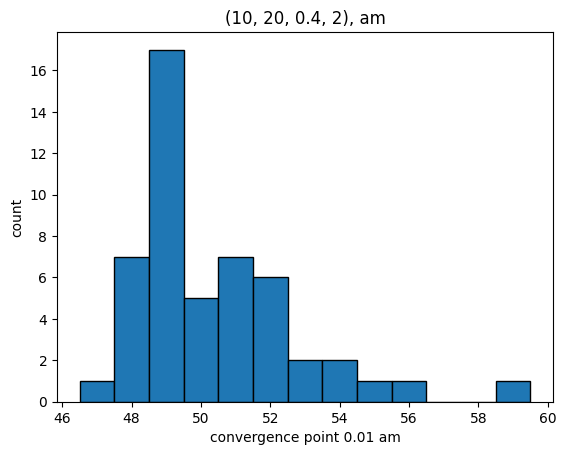

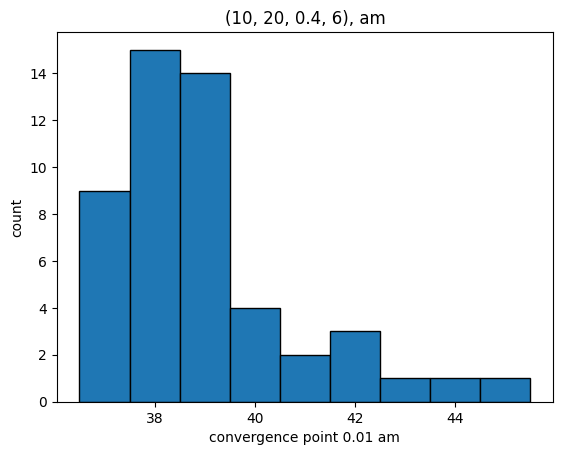

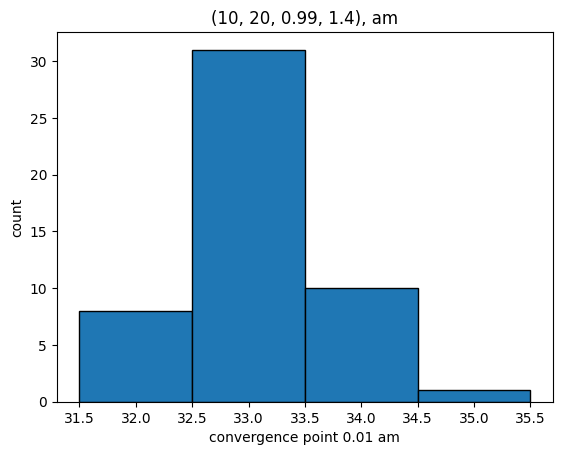

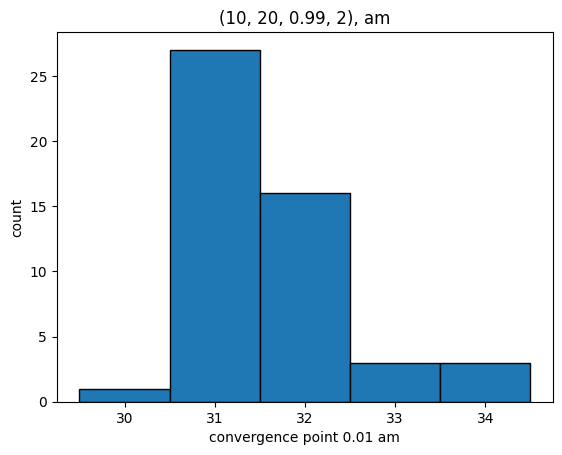

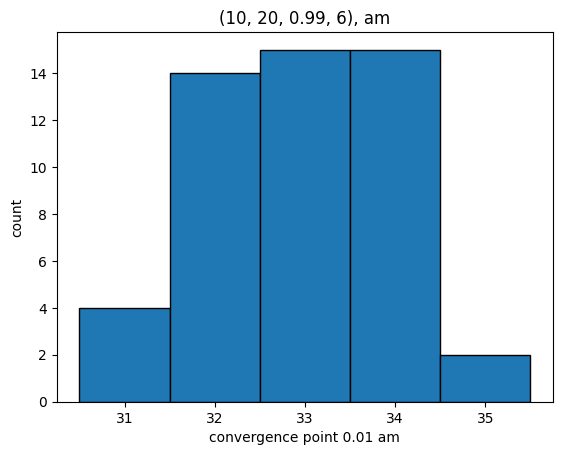

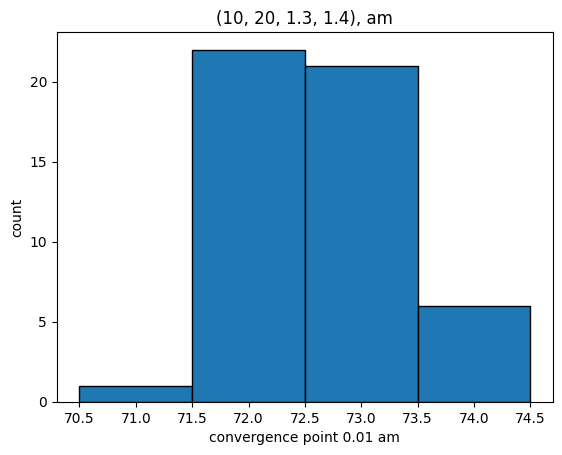

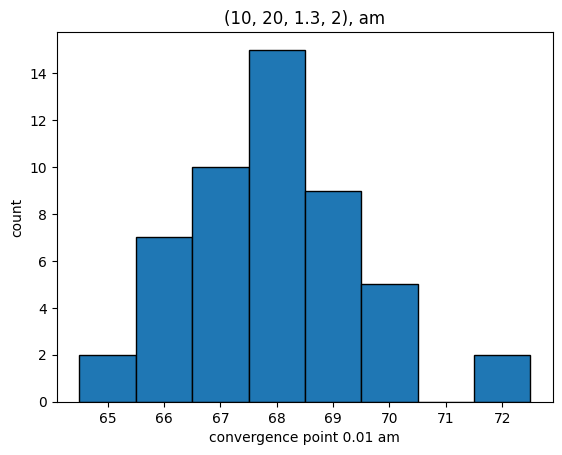

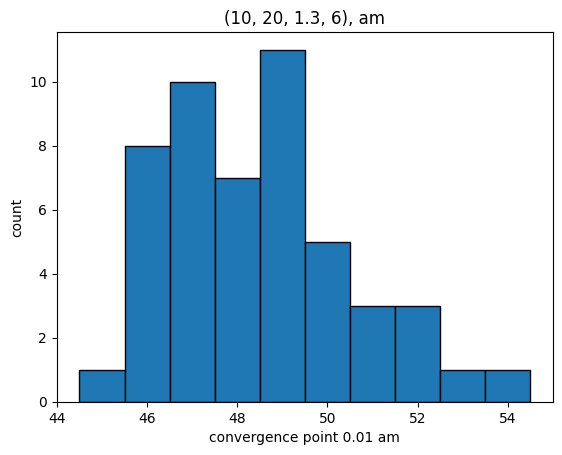

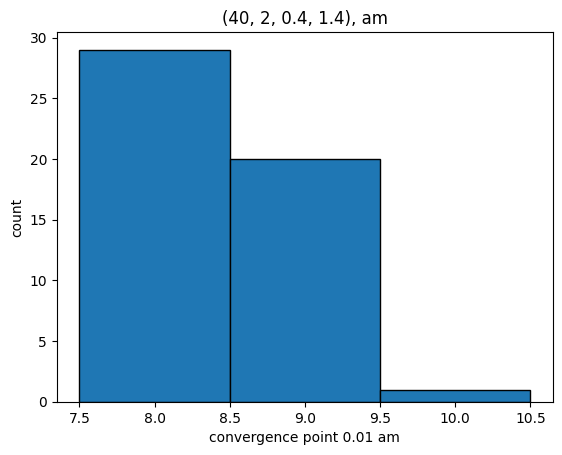

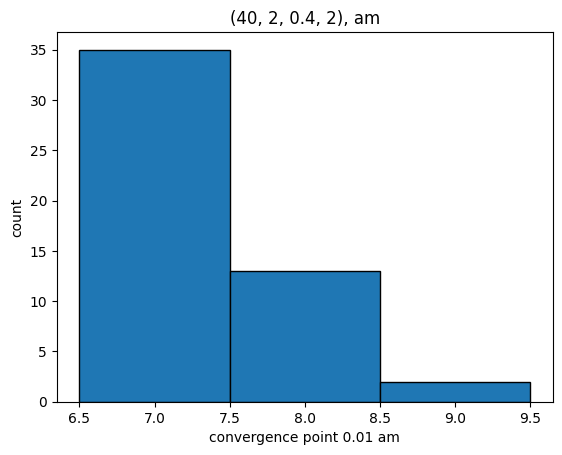

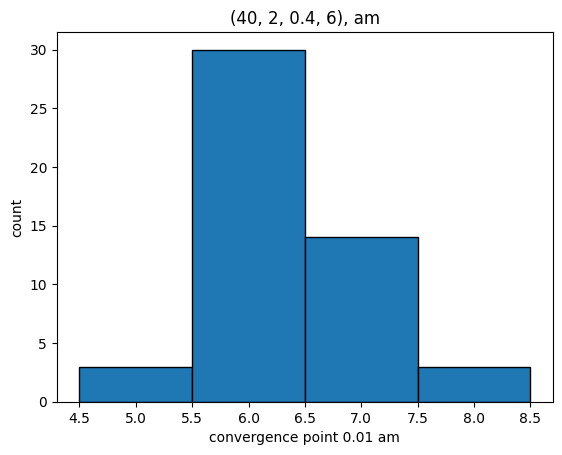

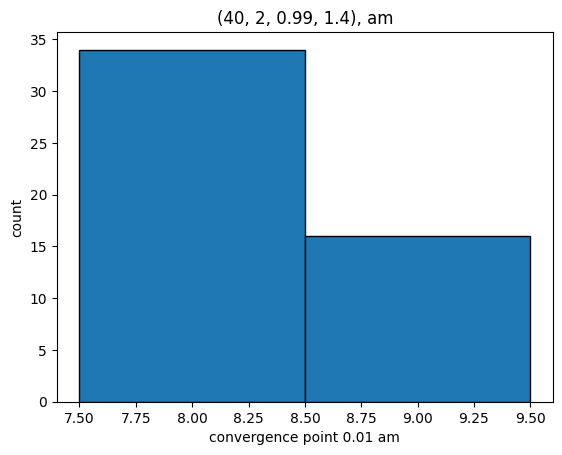

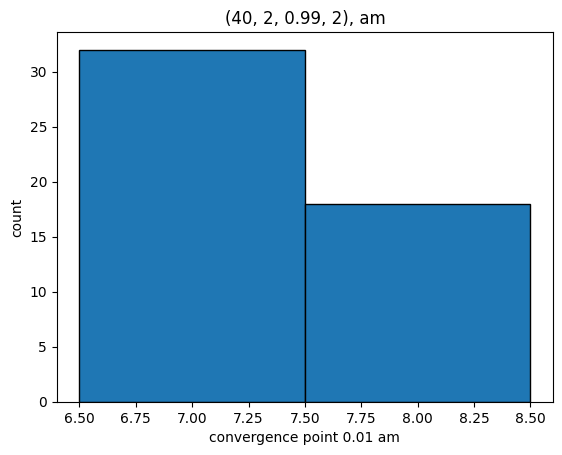

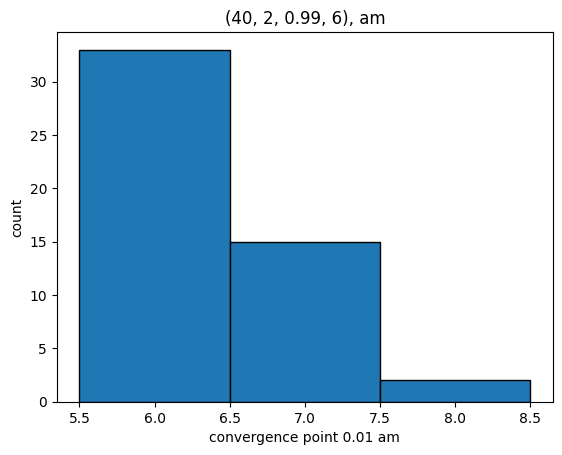

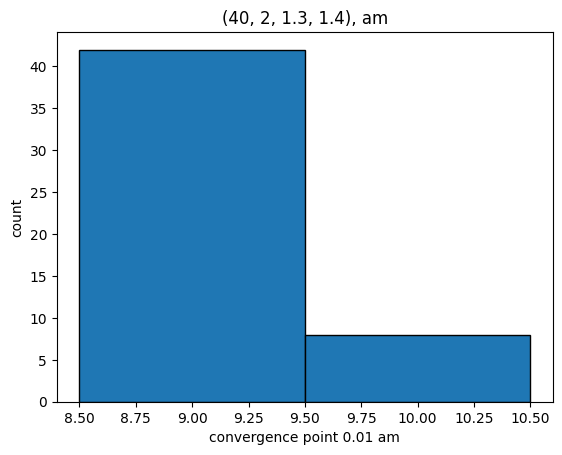

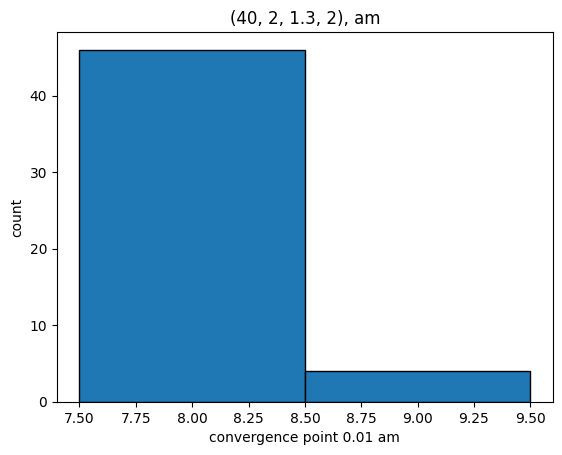

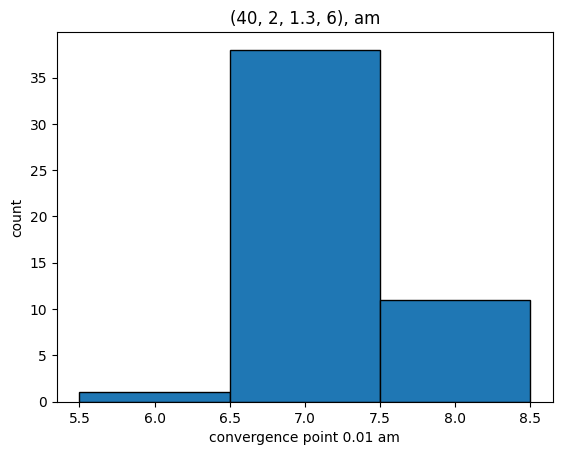

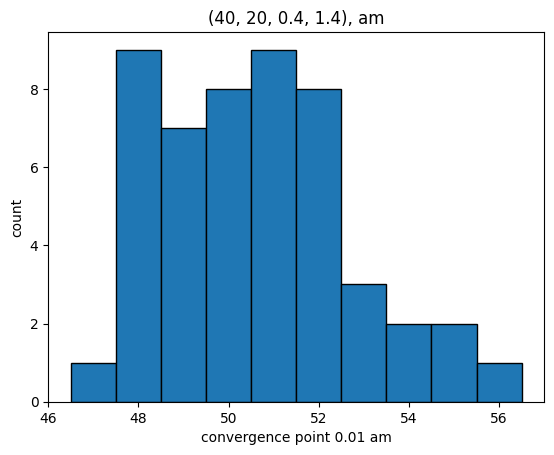

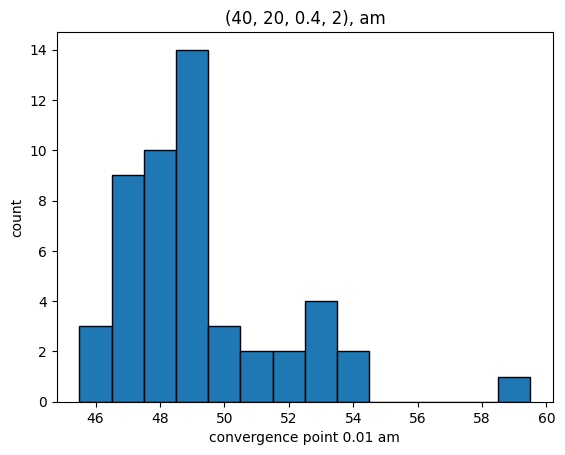

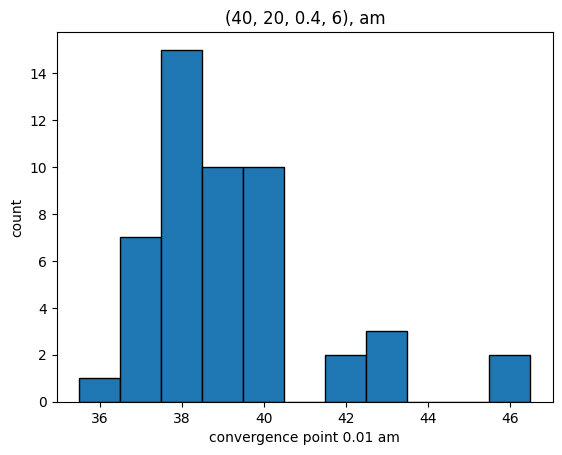

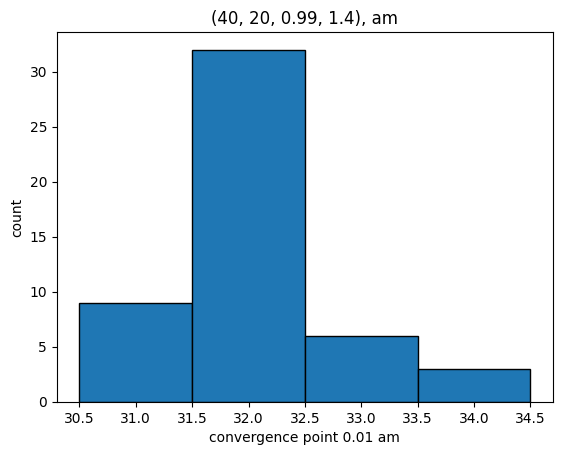

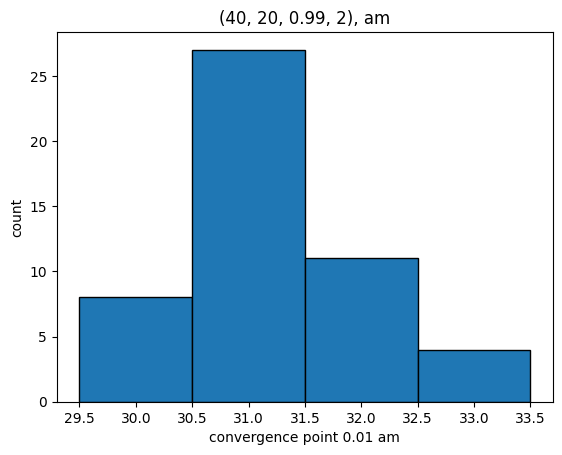

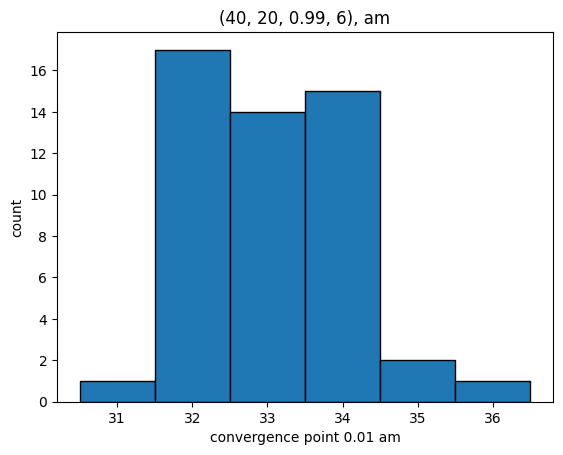

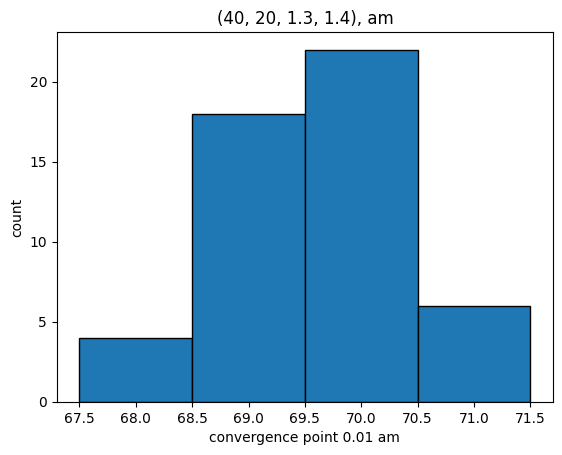

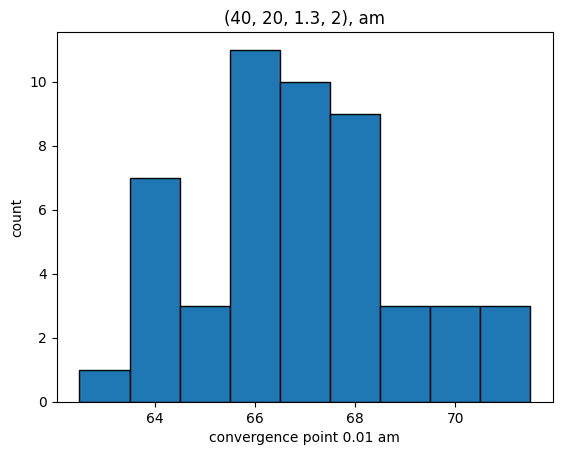

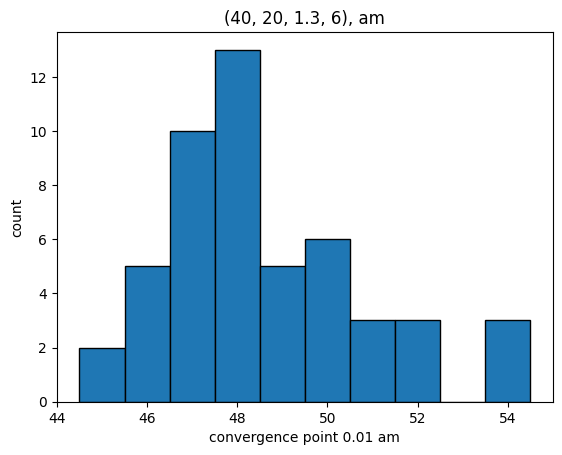

In [4]:
# Plot all file1 histograms (added mass)
wide_variation_cases = []
for idx, quad in enumerate(quads):
  vals = histogram(fixed_prob_lsts[idx],"am", 0.01, ylab = "count", title = f"{quad}, am")
  if max(vals) - min(vals) > 7:
    wide_variation_cases.append(idx)

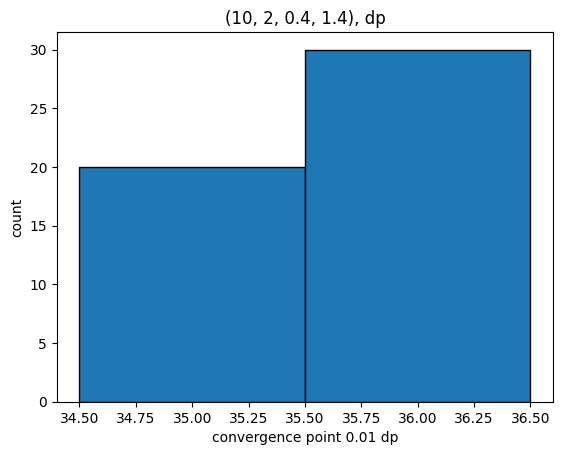

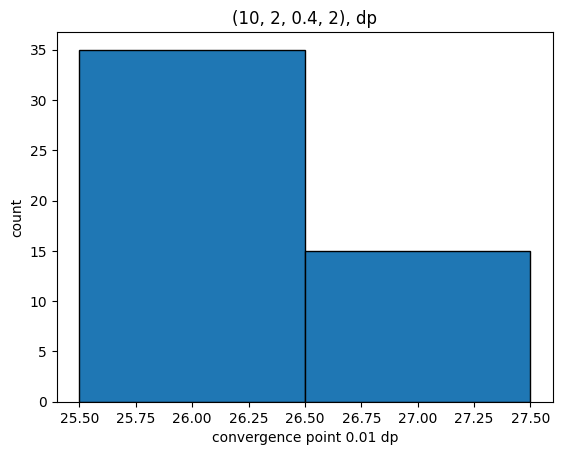

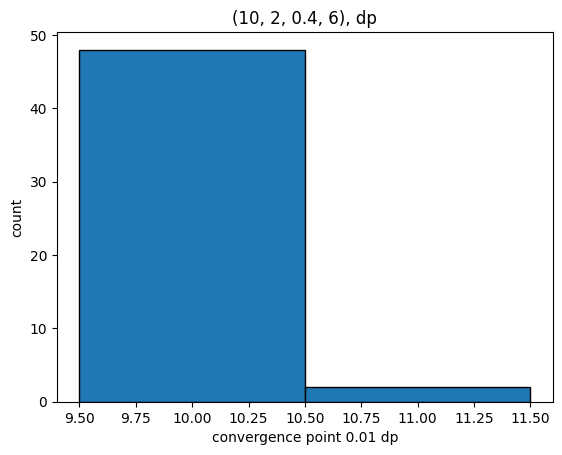

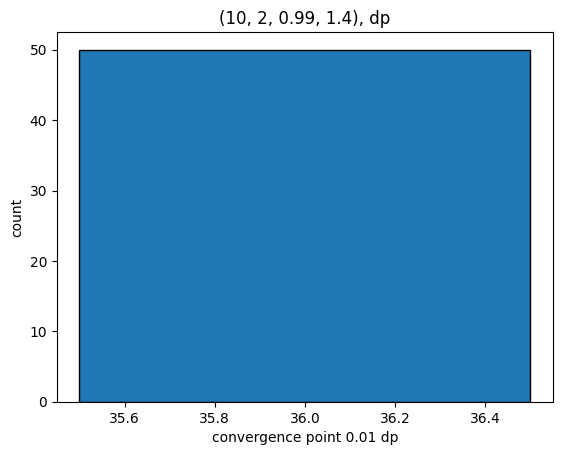

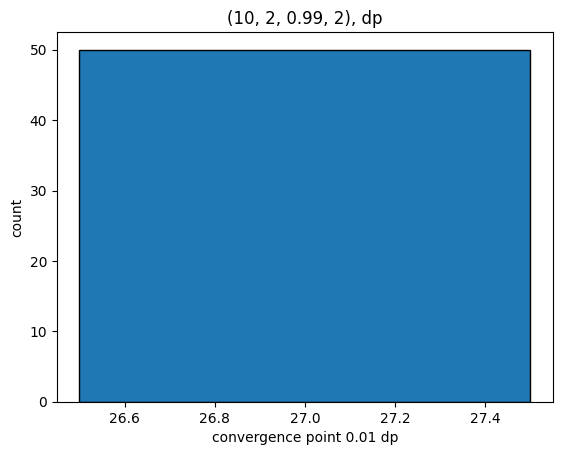

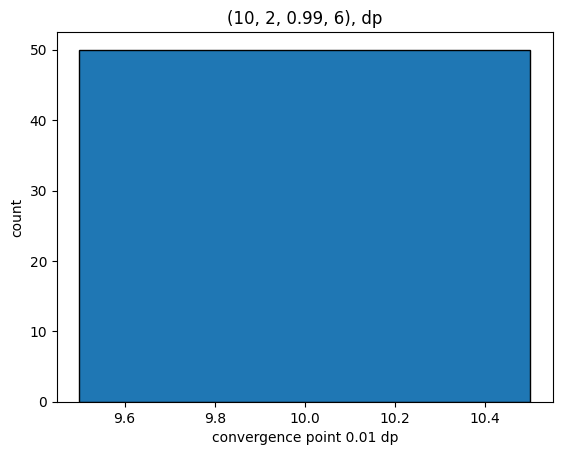

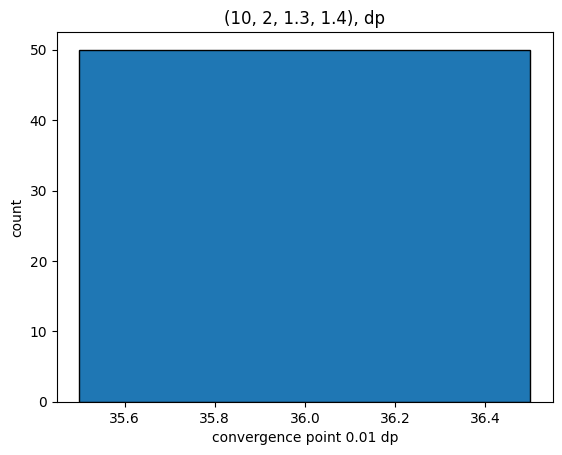

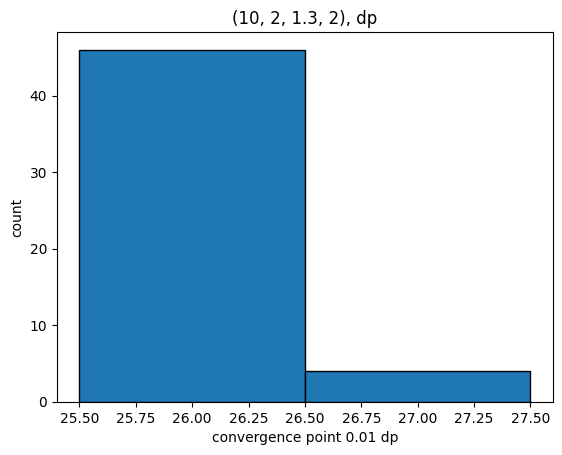

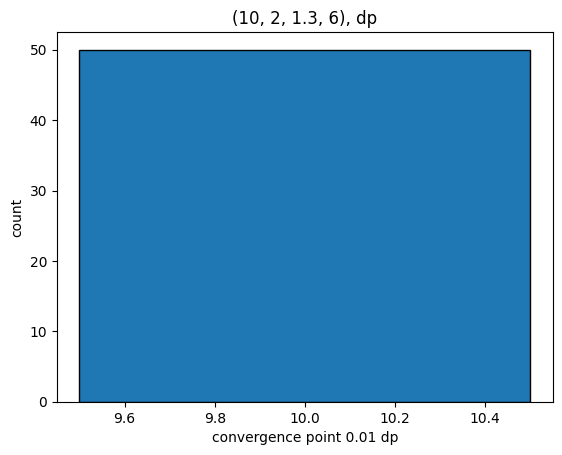

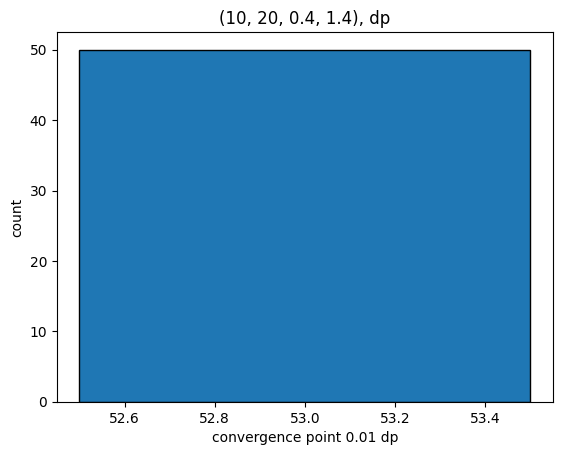

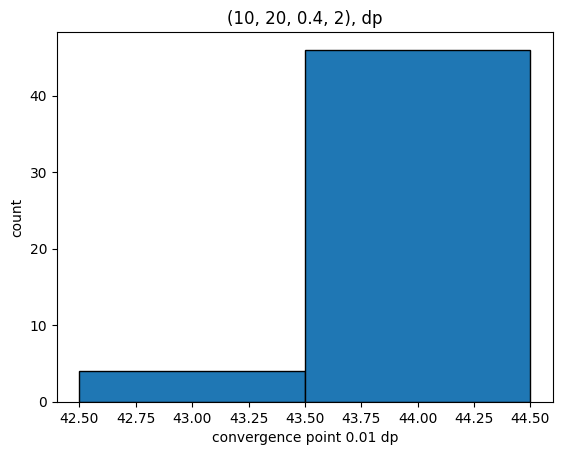

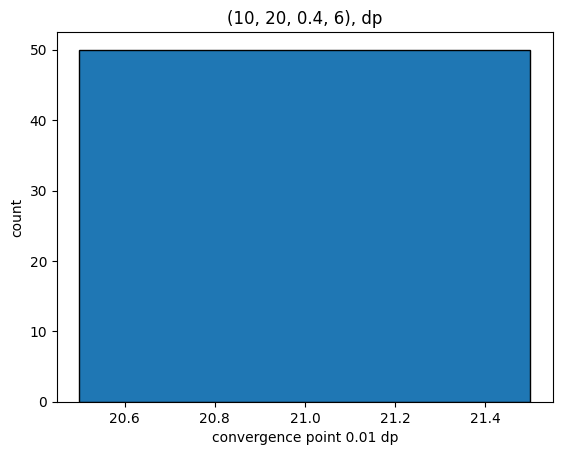

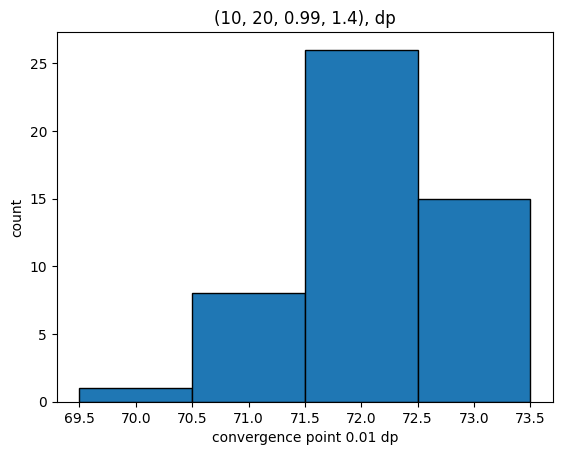

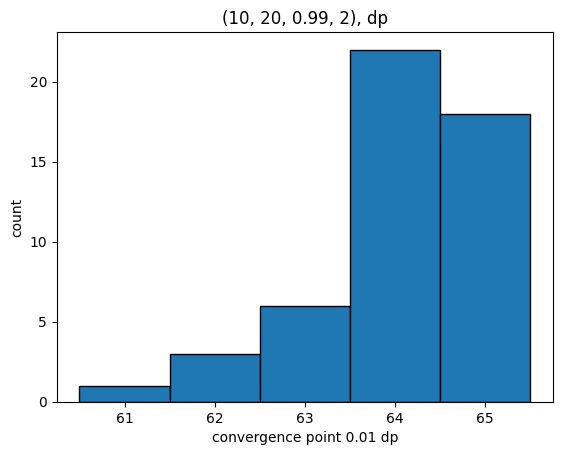

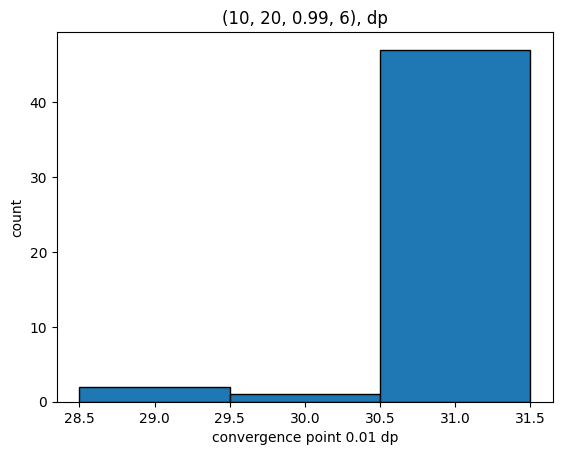

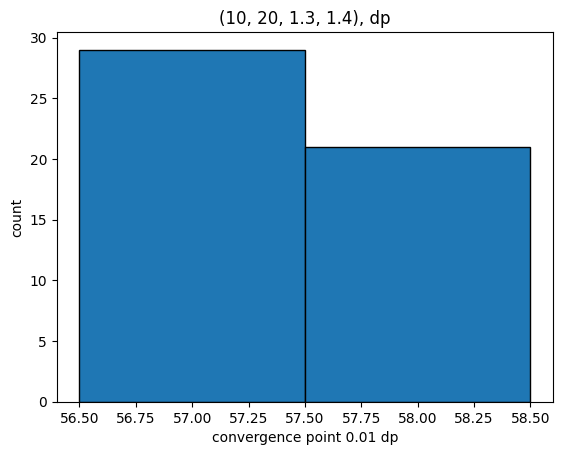

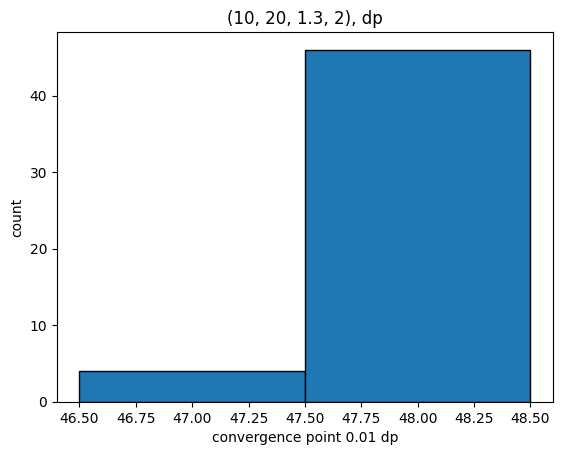

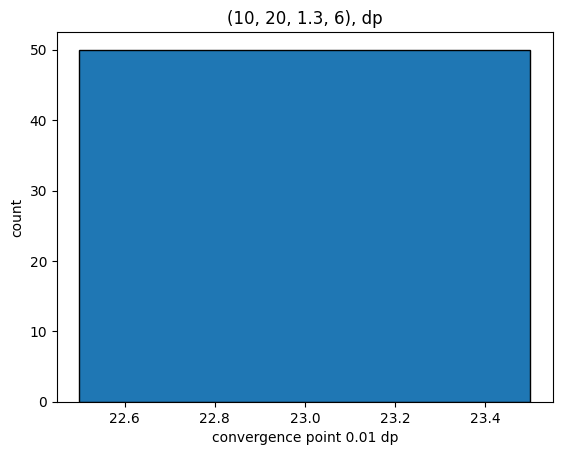

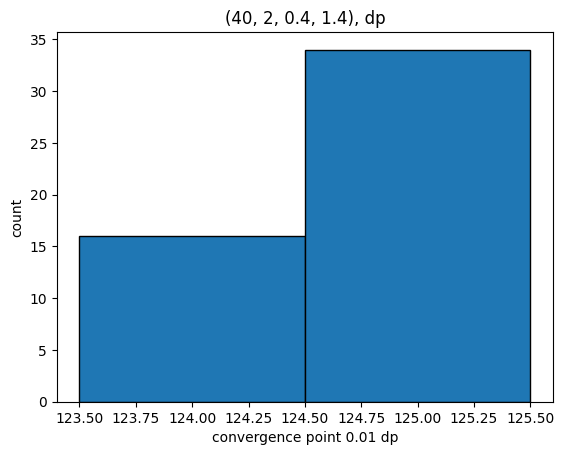

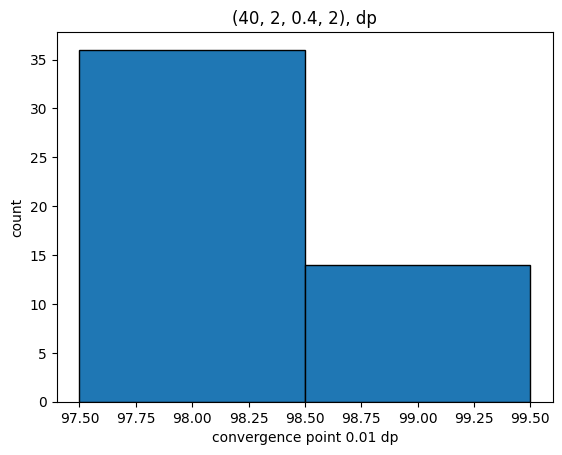

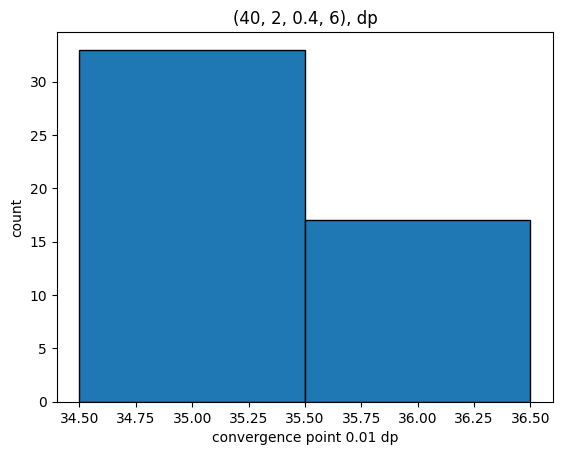

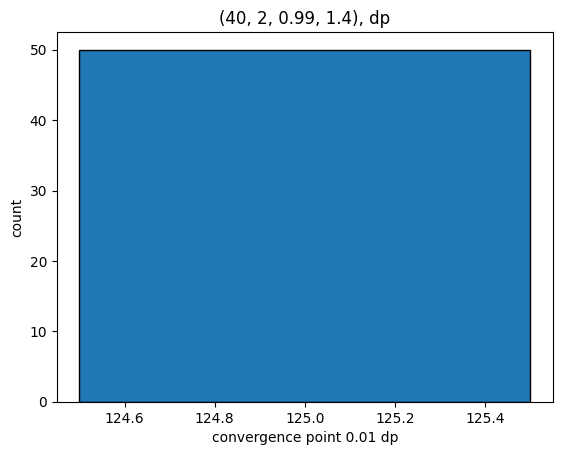

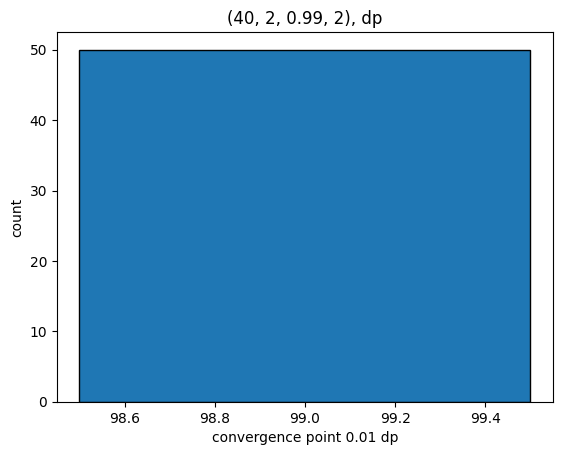

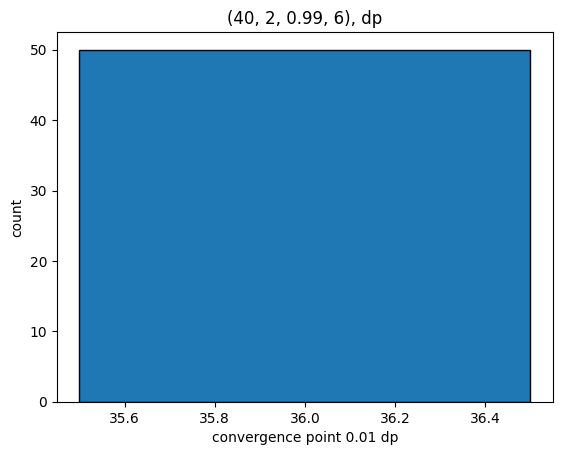

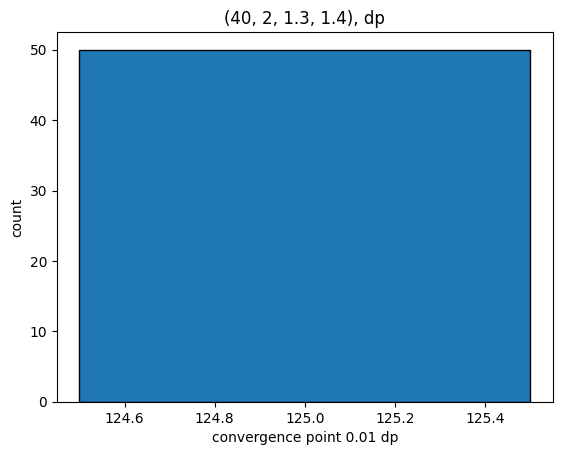

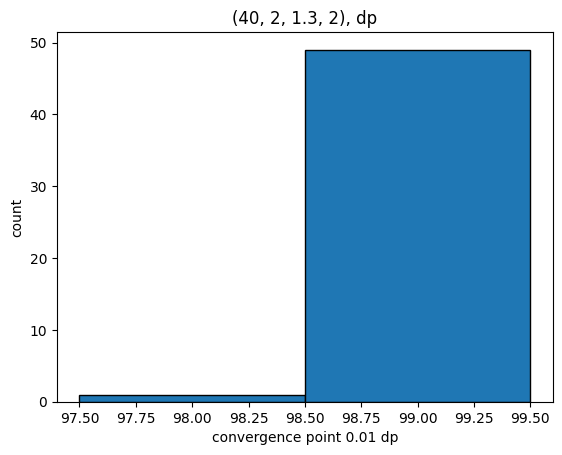

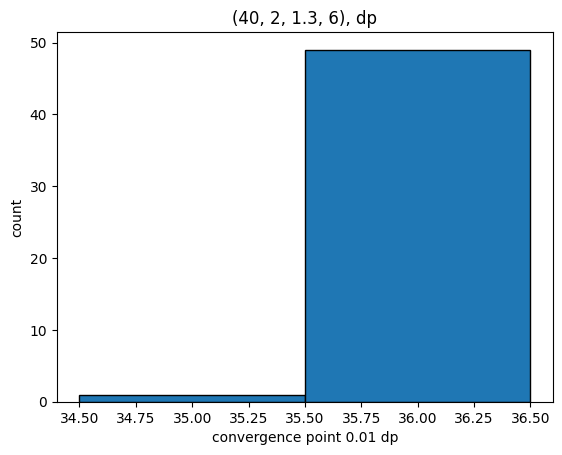

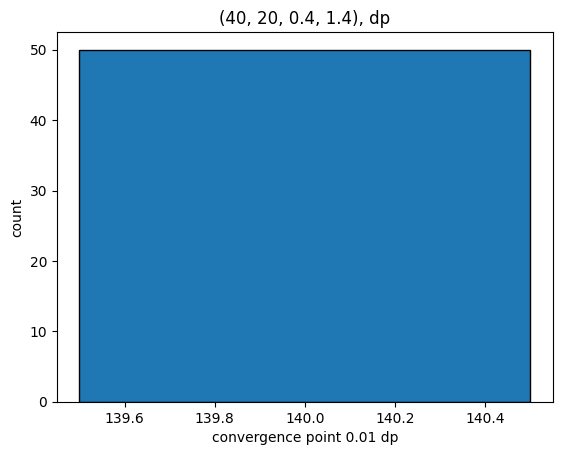

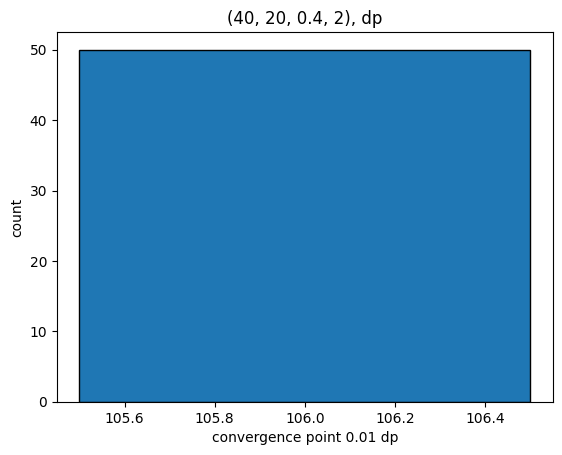

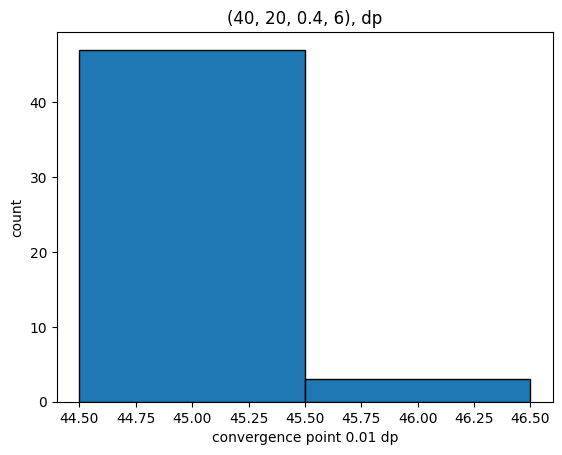

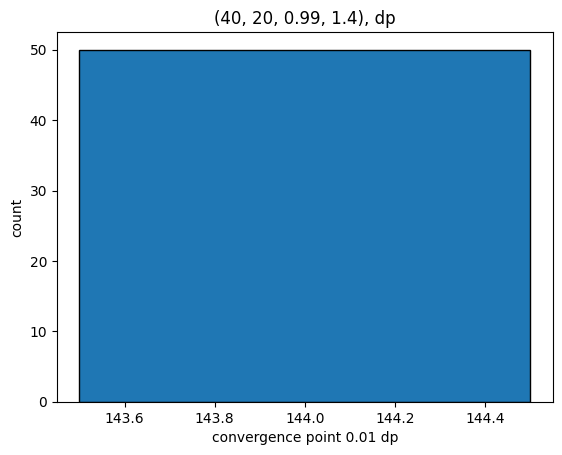

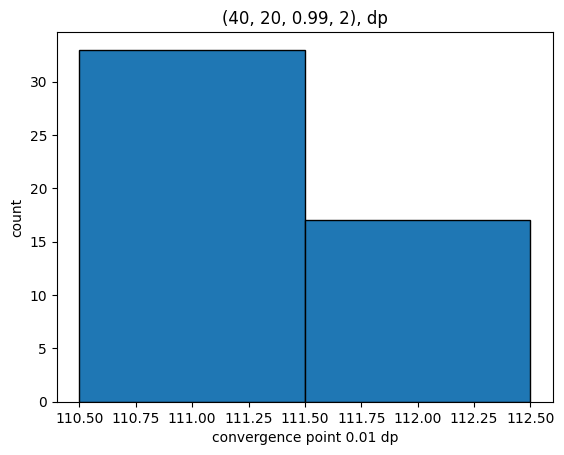

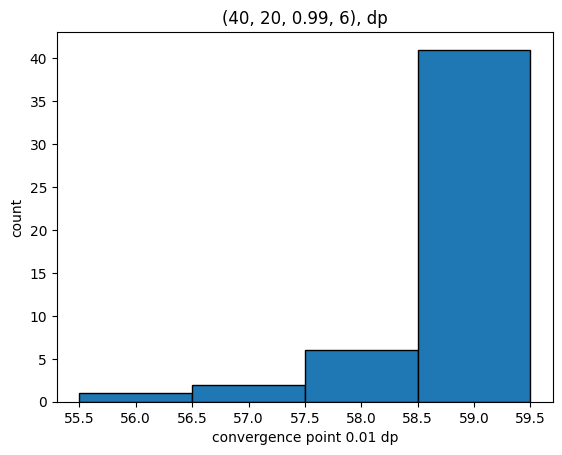

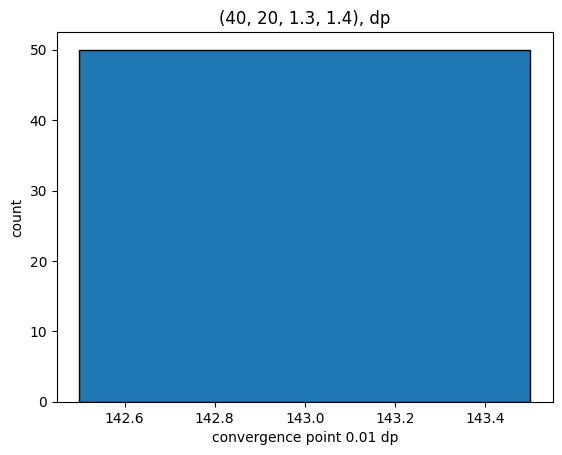

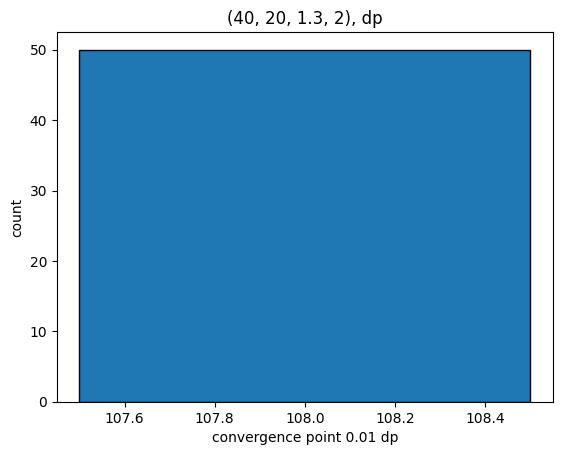

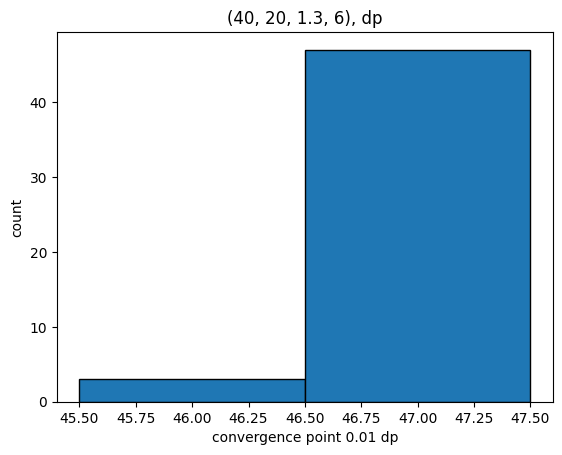

In [9]:
# Plot all file1 histograms (damping)
# wide_variation_cases = []
for idx, quad in enumerate(quads):
  vals = histogram(fixed_prob_lsts[idx],"dp", 0.01, ylab = "count", title = f"{quad}, dp")
  # if max(vals) - min(vals) > 10:
  #   wide_variation_cases.append(idx)

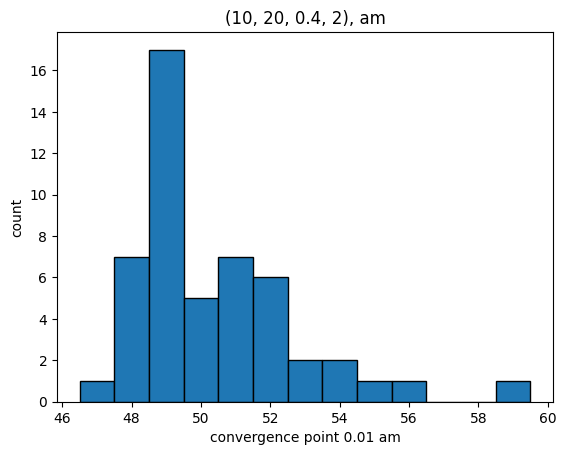

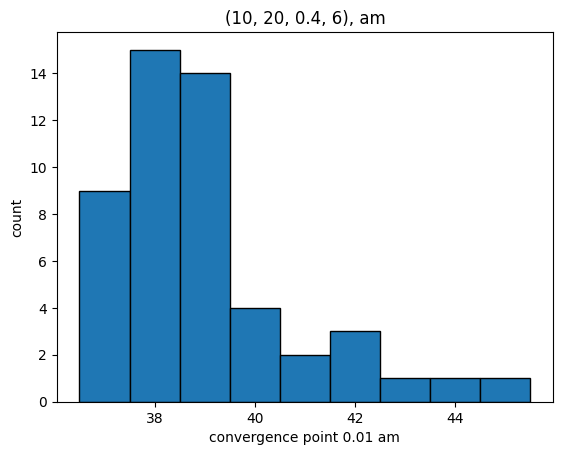

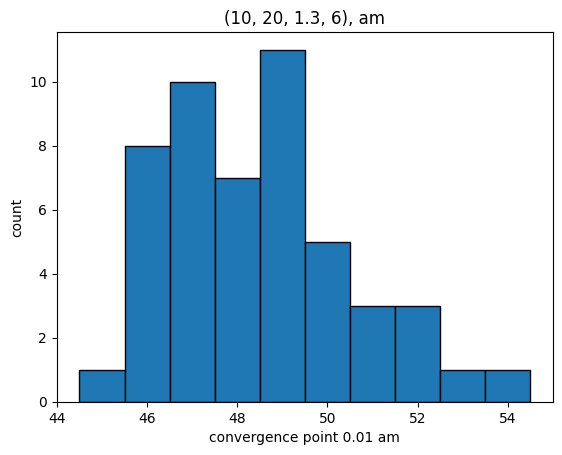

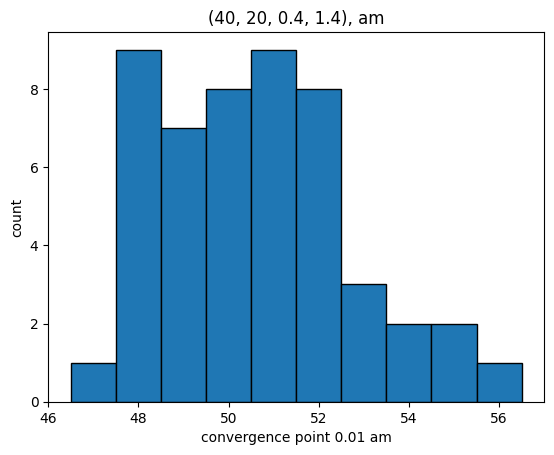

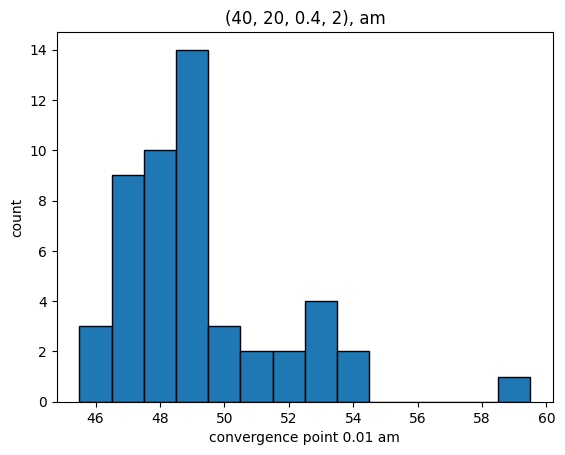

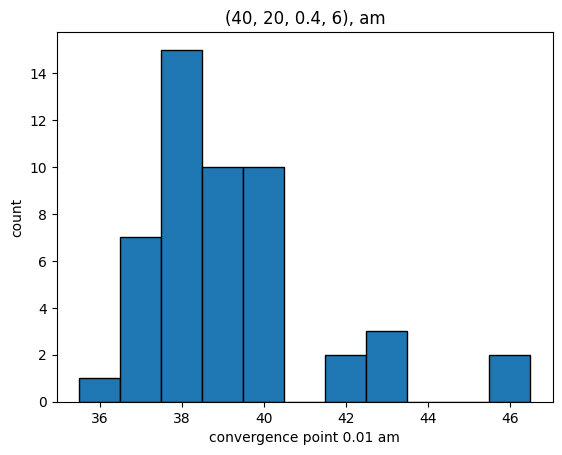

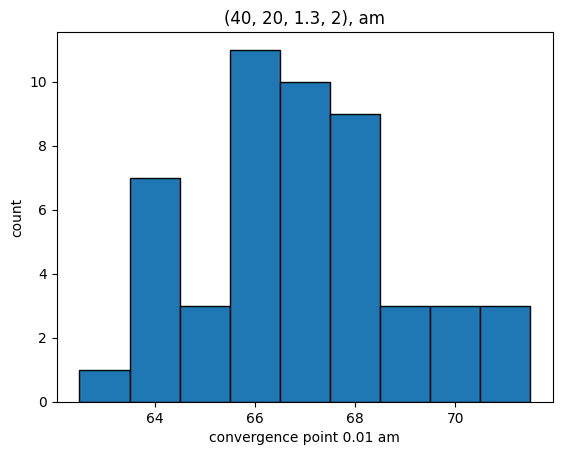

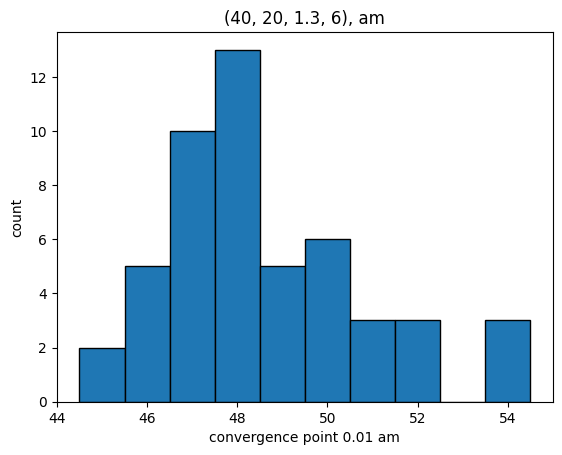

In [10]:
# file1 histograms with wide range of convergence points (added mass)
for idx, quad in enumerate(quads):
  if idx in wide_variation_cases:
    histogram(fixed_prob_lsts[idx],"am", 0.01, ylab = "count", title = f"{quad}, am")

In [11]:
# Geometry plotting function, bluer color means faster convergence.
def plot_varied_cases(fixed_prob_lsts, idx):
  subset = fixed_prob_lsts[idx].copy()
  val_func = lambda data: data[data["m0s"][0]]["convergence point 0.01 am"]
  subset.sort(key = val_func)
  vals = [val_func(data) for data in subset]
  filter_and_plot_shapes(subset, lambda data_dict, m0 : True, 
                        lambda data_dict, m0 : get_plasma_color(data_dict[m0]["convergence point 0.01 am"], min_value = min(vals), max_value=max(vals)),
                        ppr = 10, figsize_per_plot = (2, 2))
  xs = [(data_dict["a"][2] - data_dict["a"][1])/data_dict["a"][2] for data_dict in subset]
  ys = [data_dict[data_dict["m0s"][0]]["convergence point 0.01 am"] for data_dict in subset]
  plt.plot(xs, ys)
  plt.xlabel("radwidth2/(total body radius)")
  plt.ylabel("convergence point")
  plt.show()

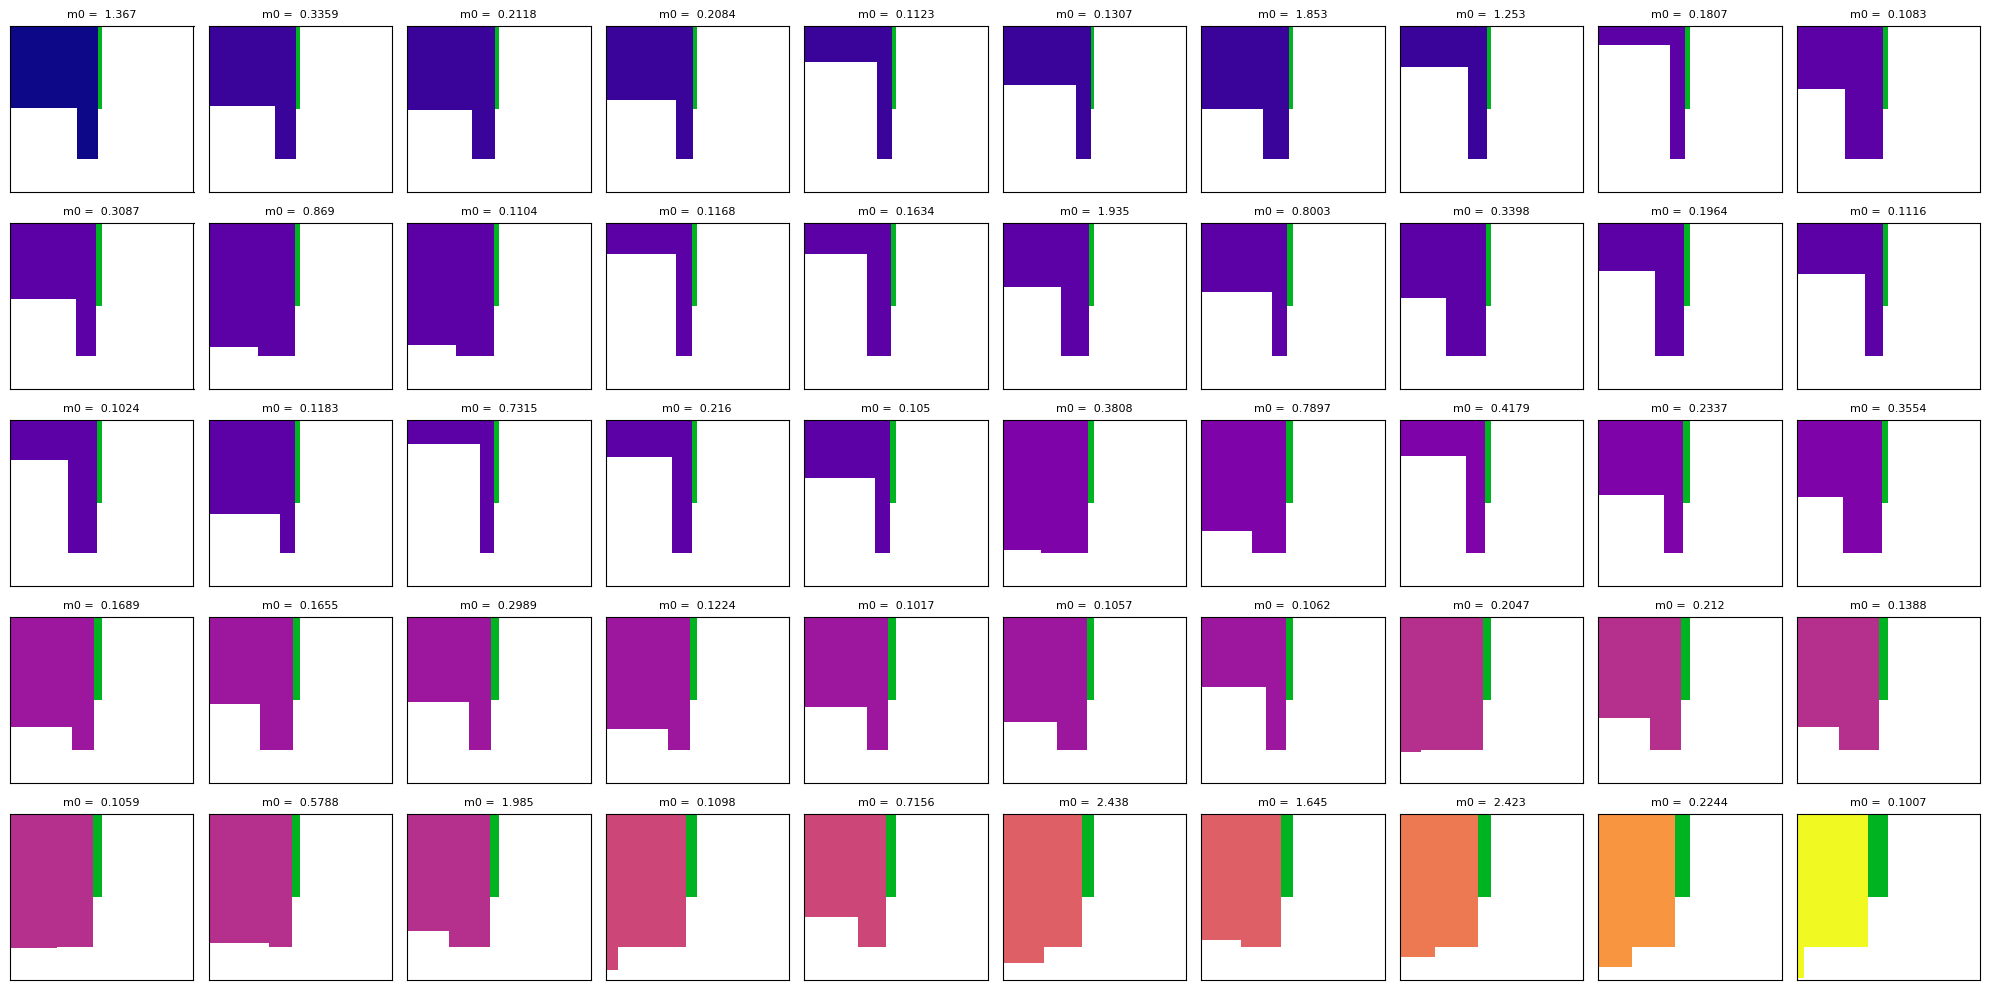

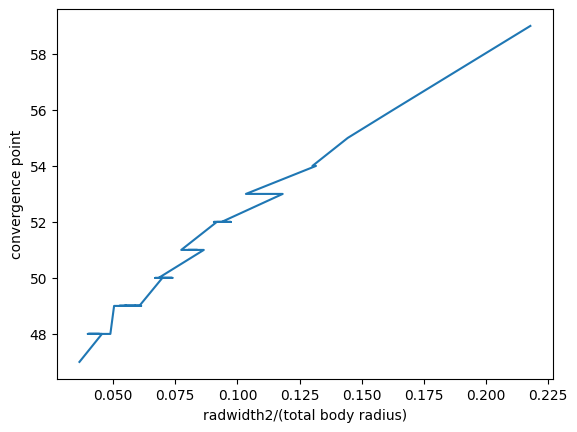

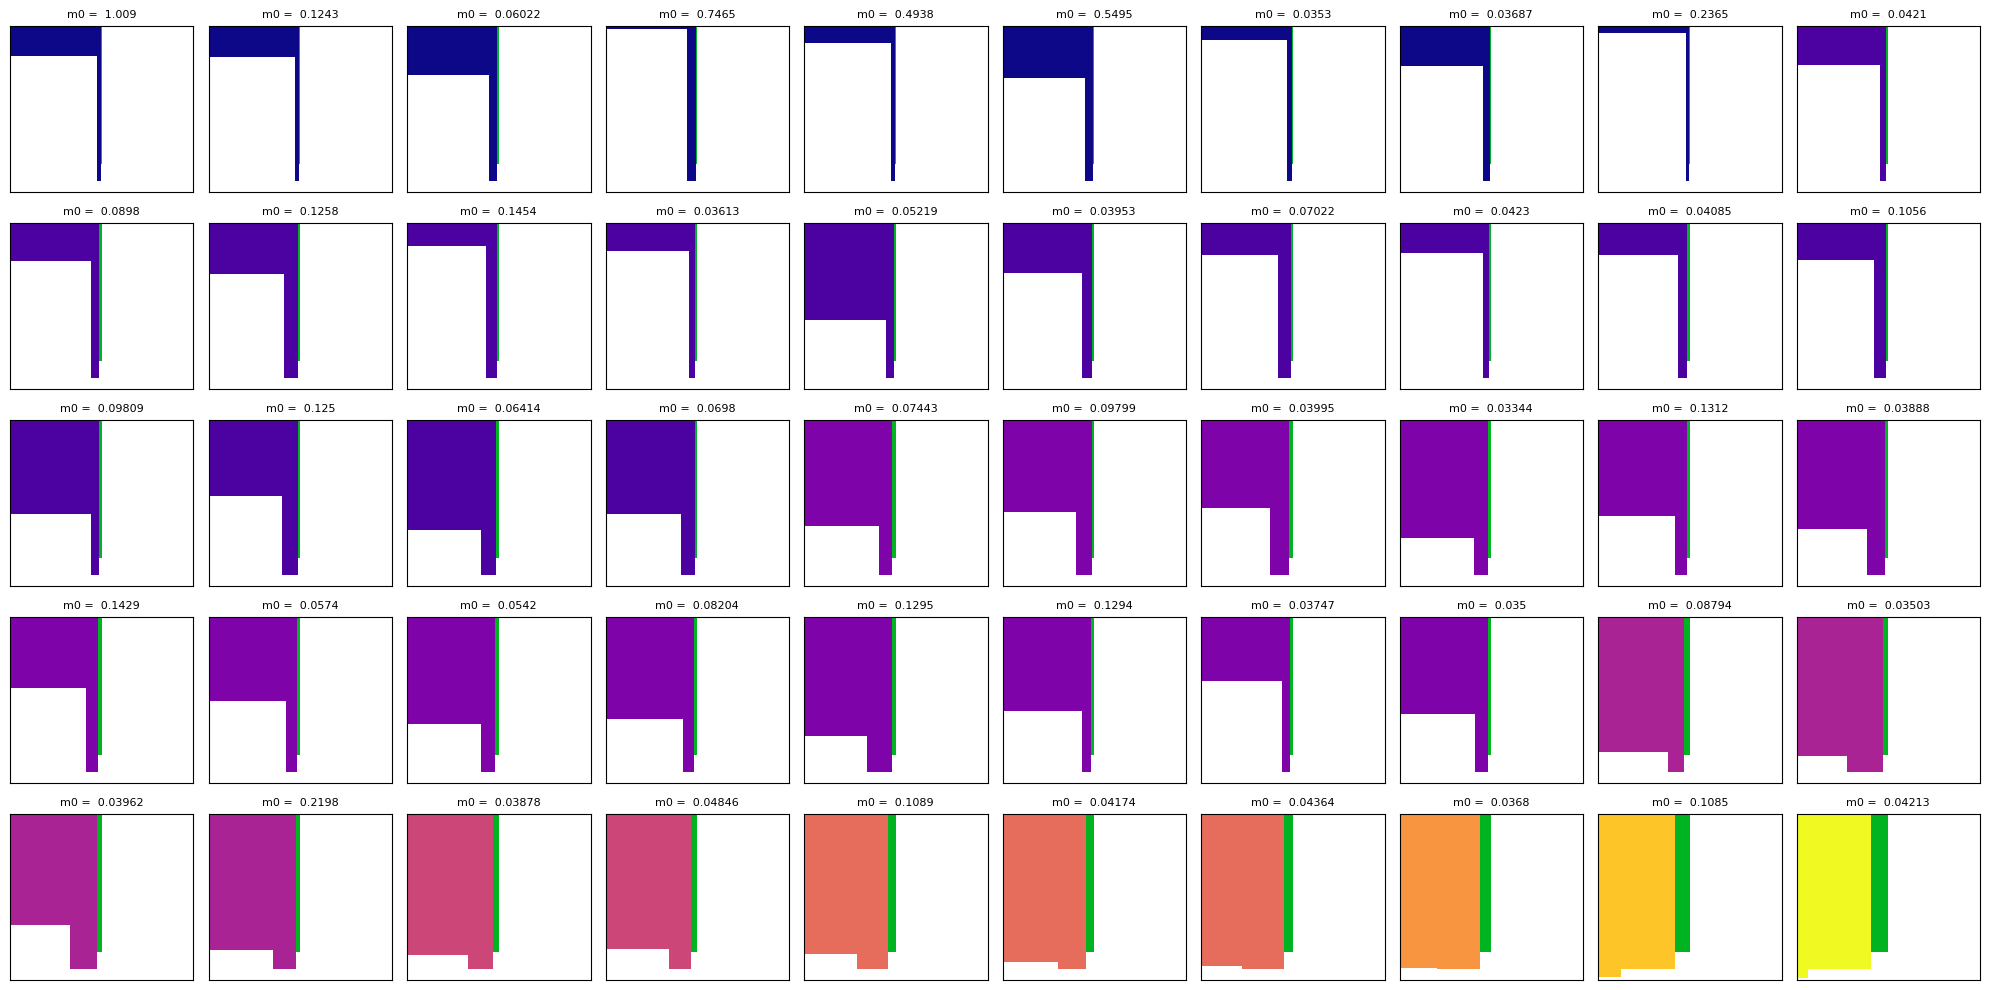

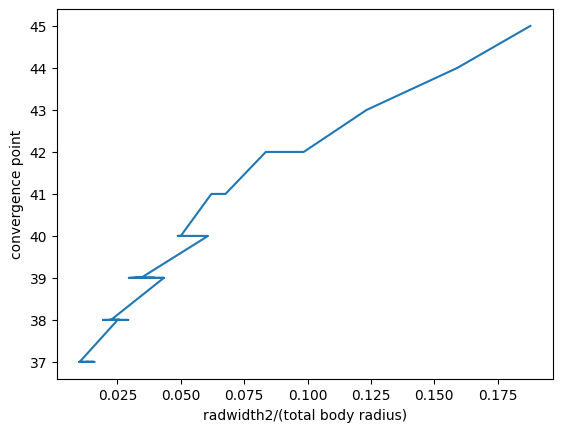

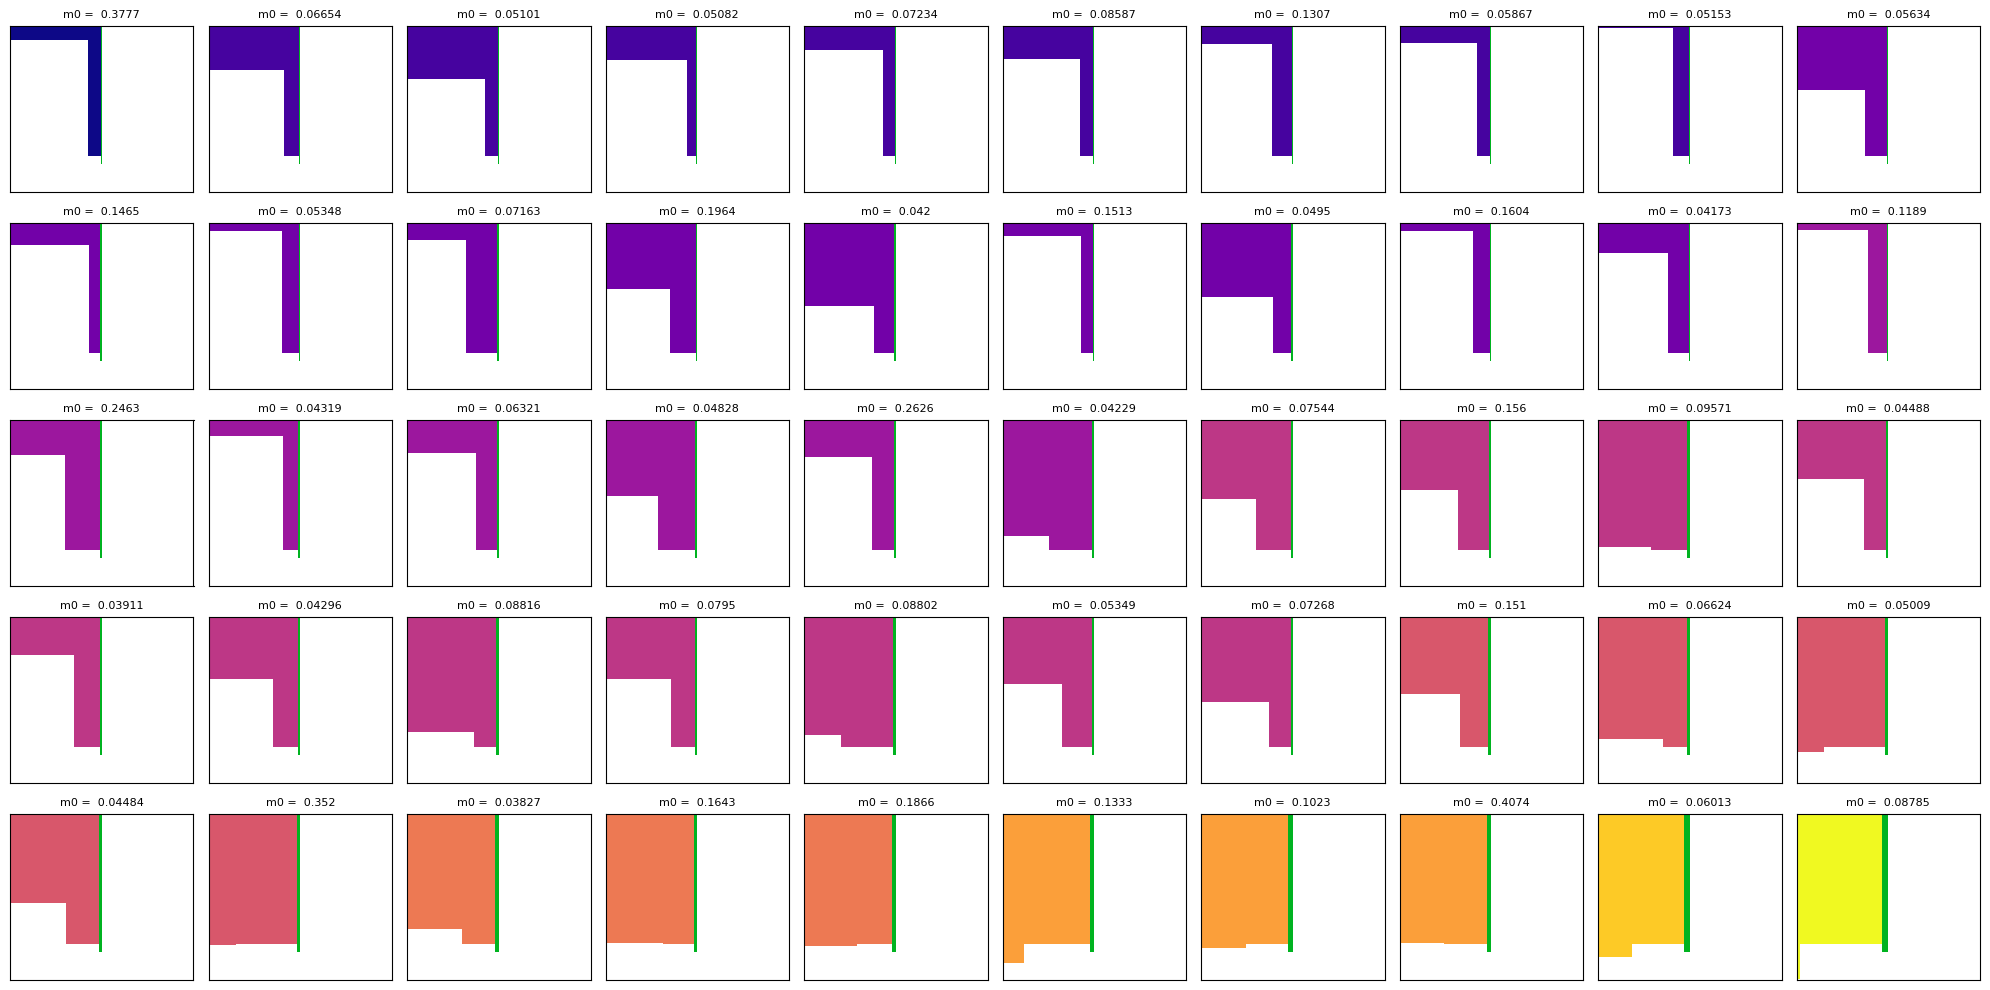

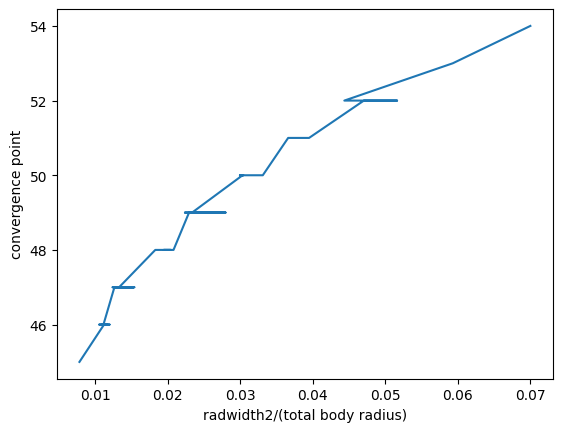

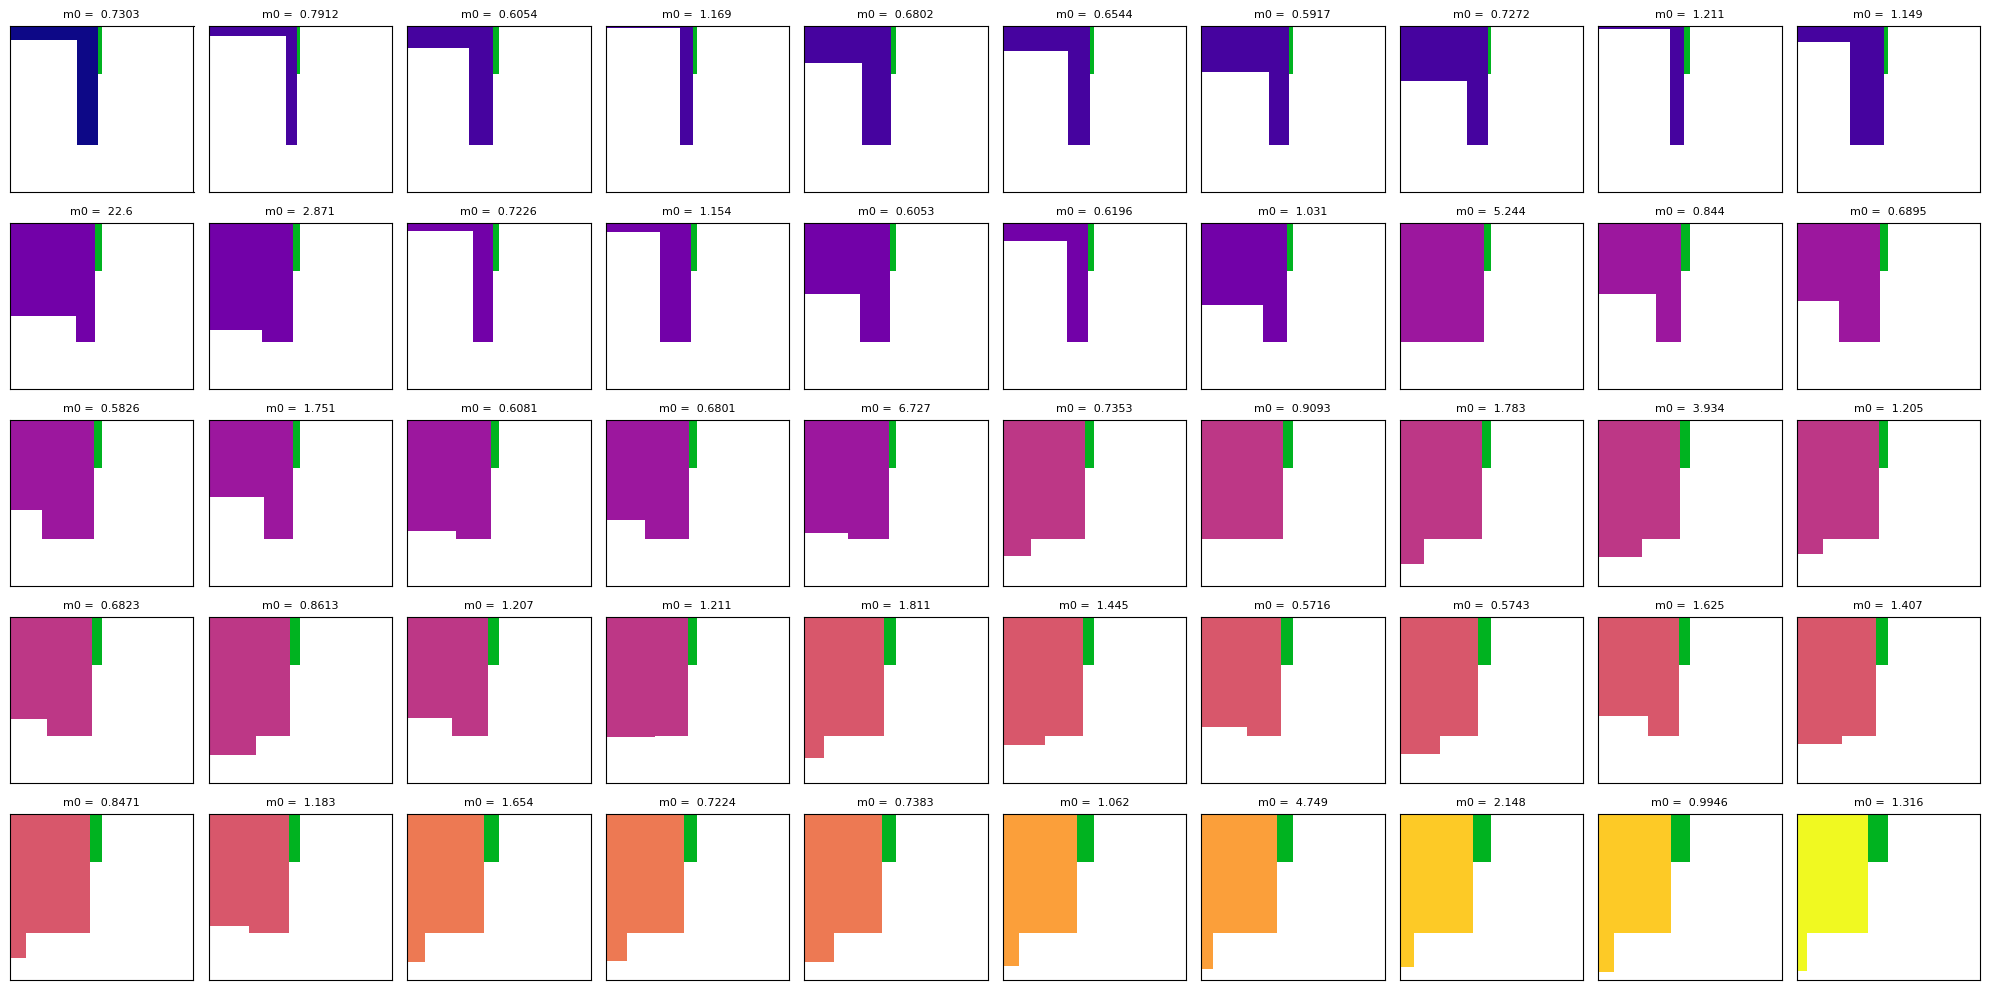

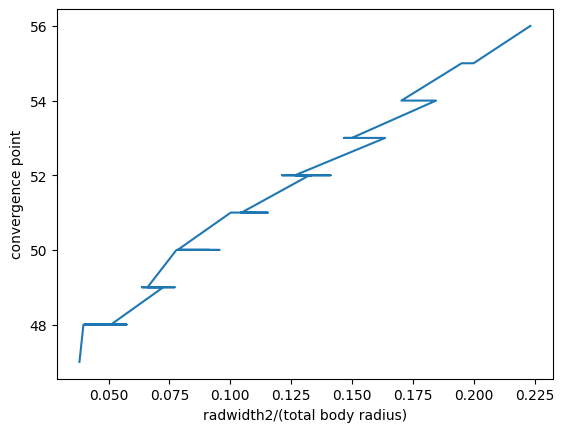

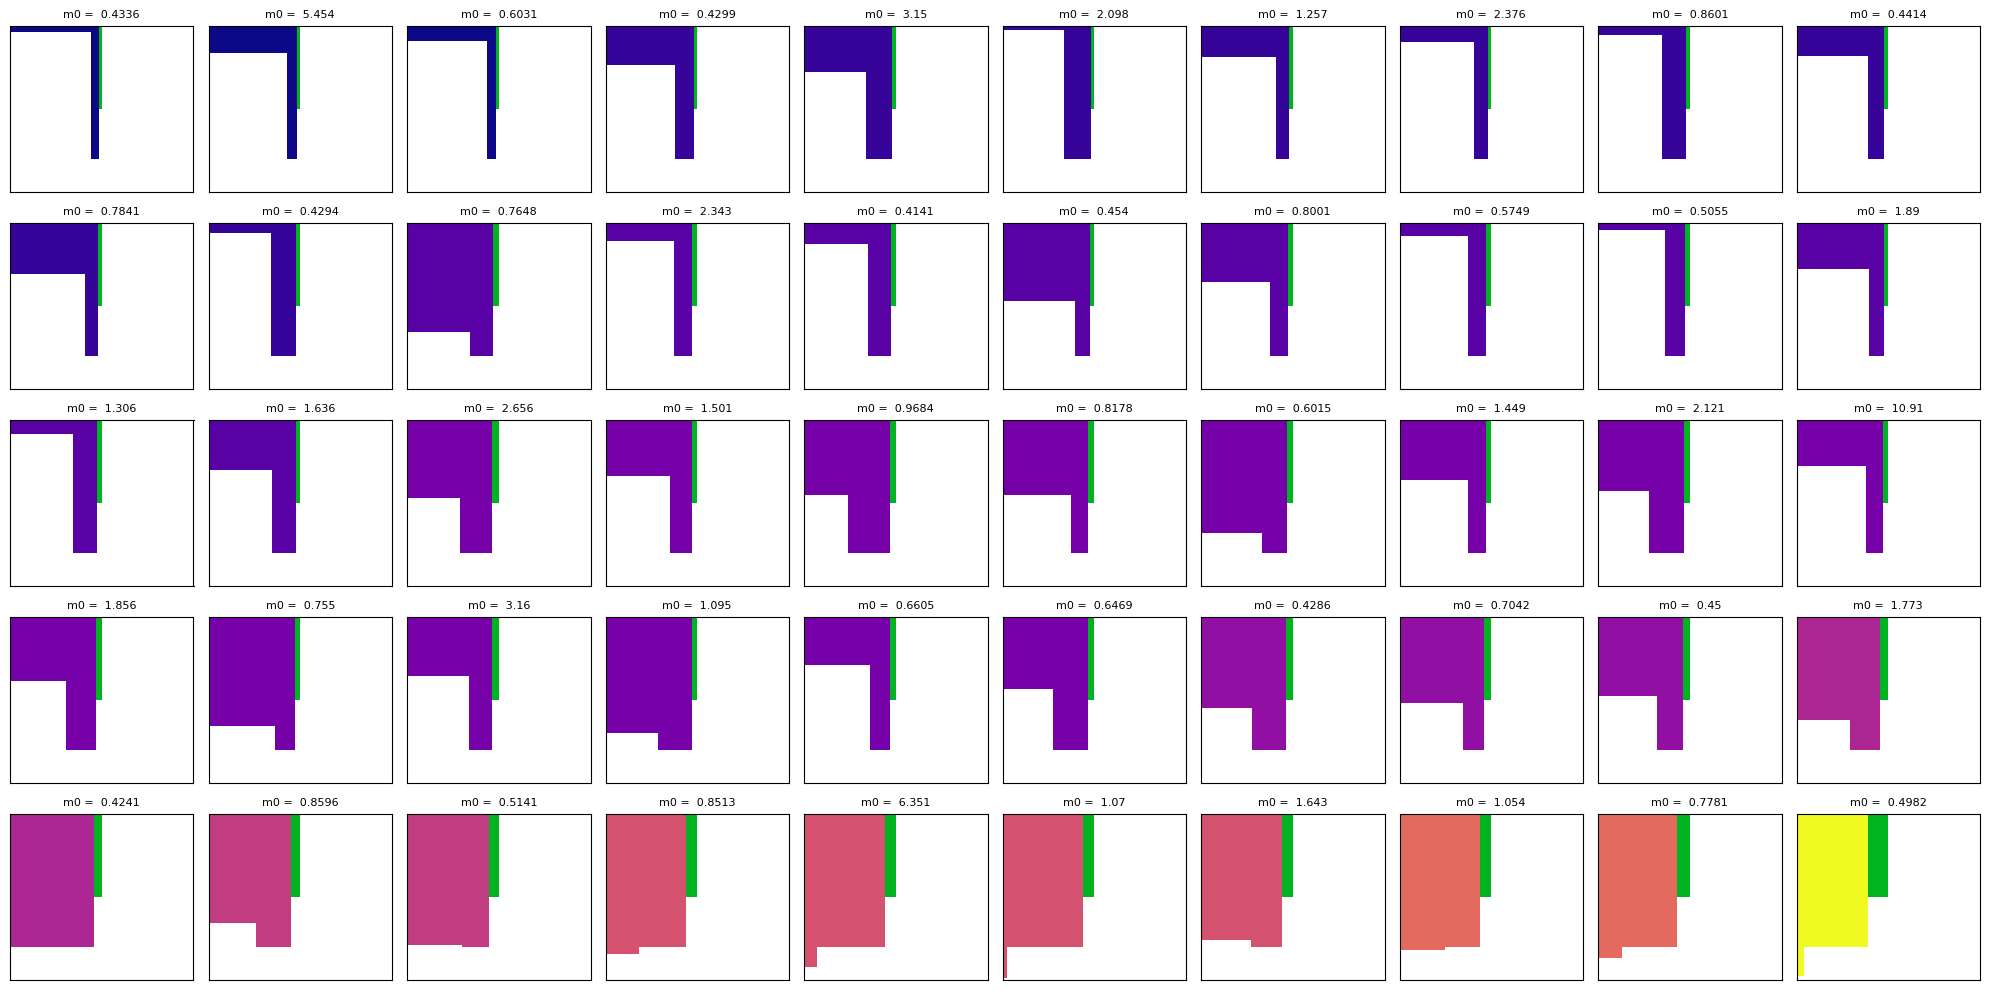

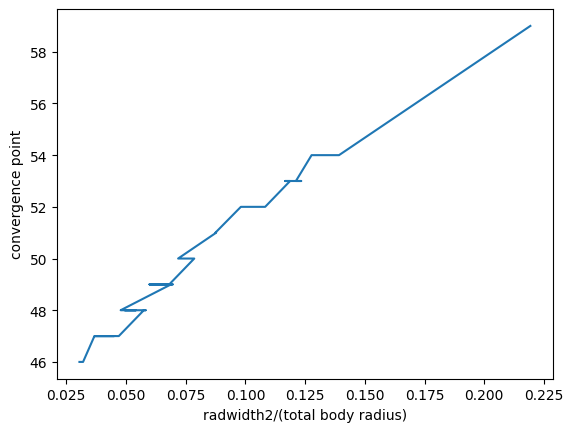

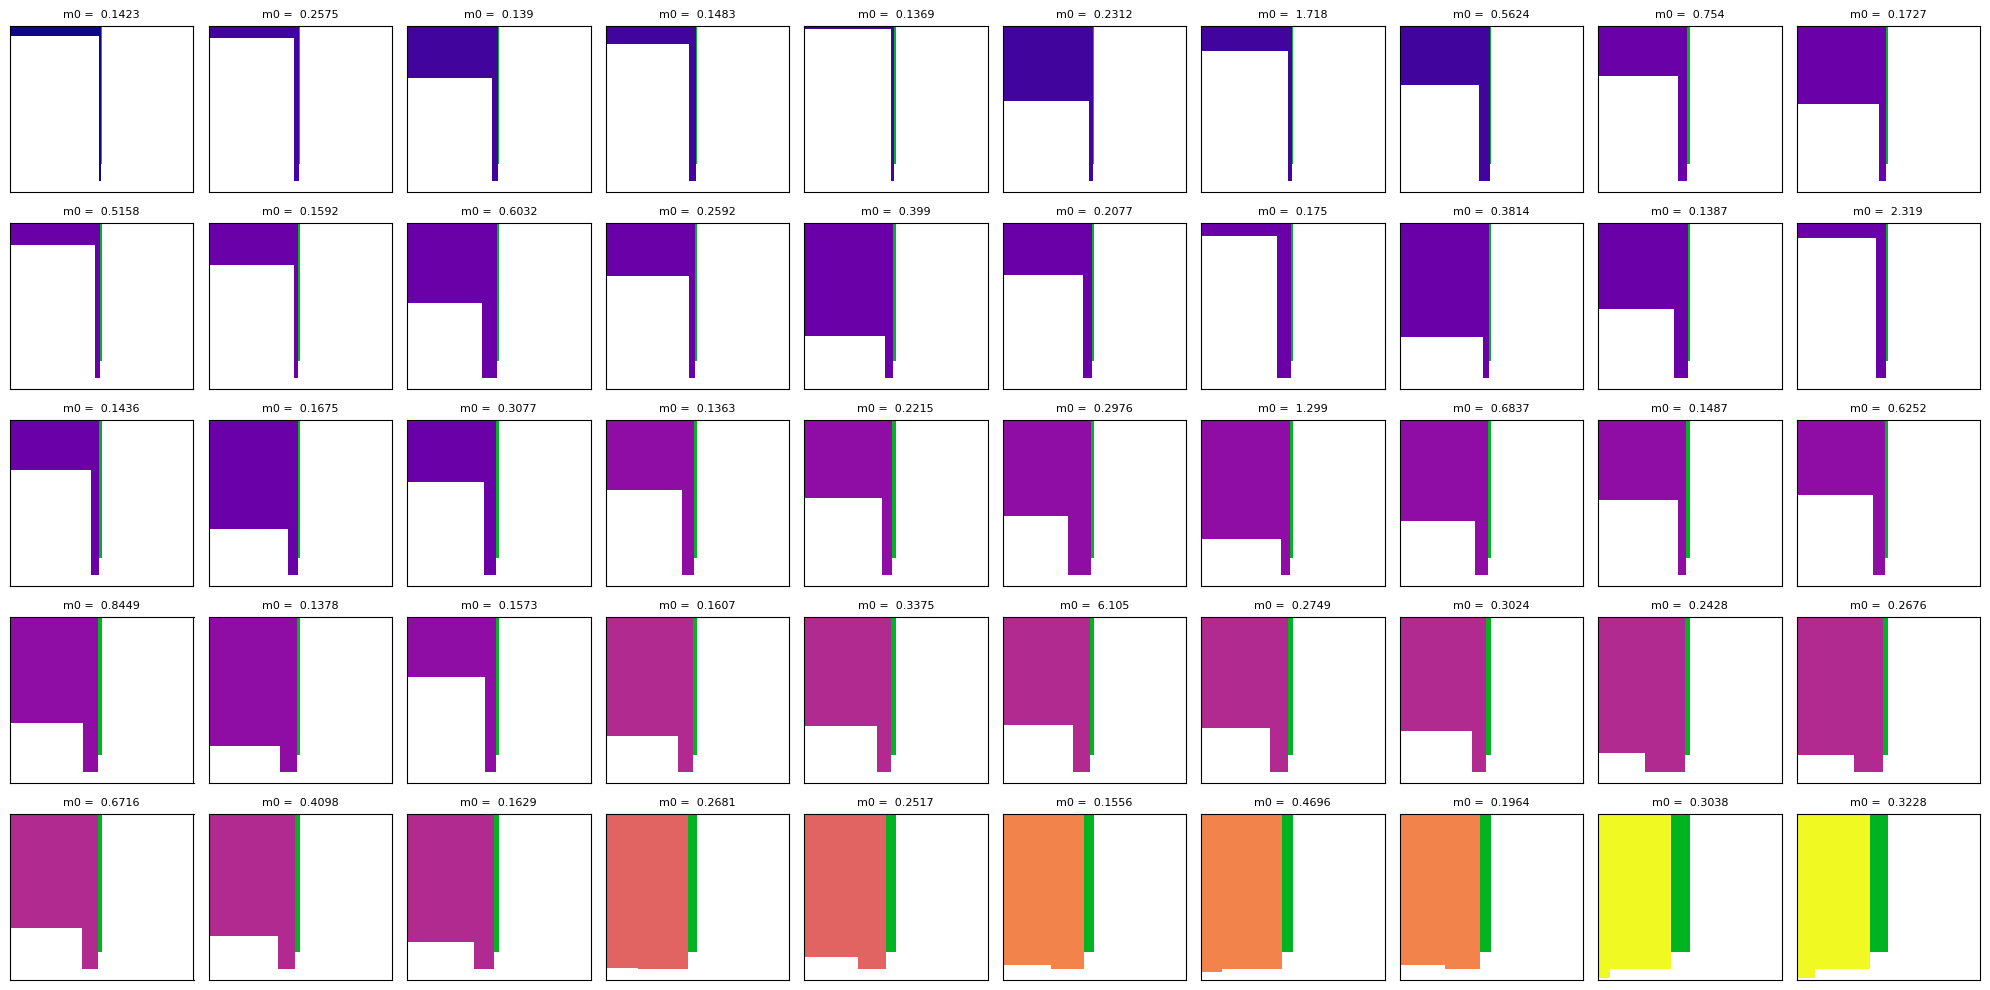

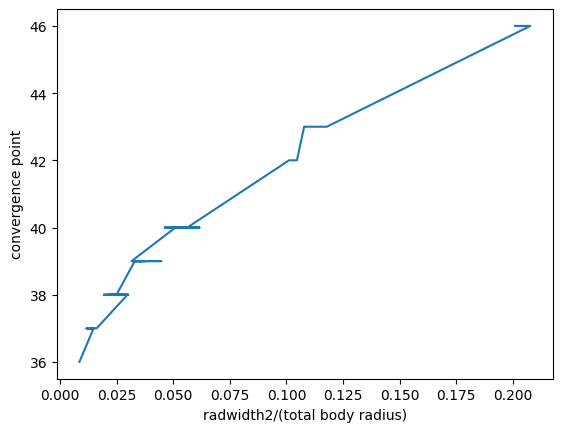

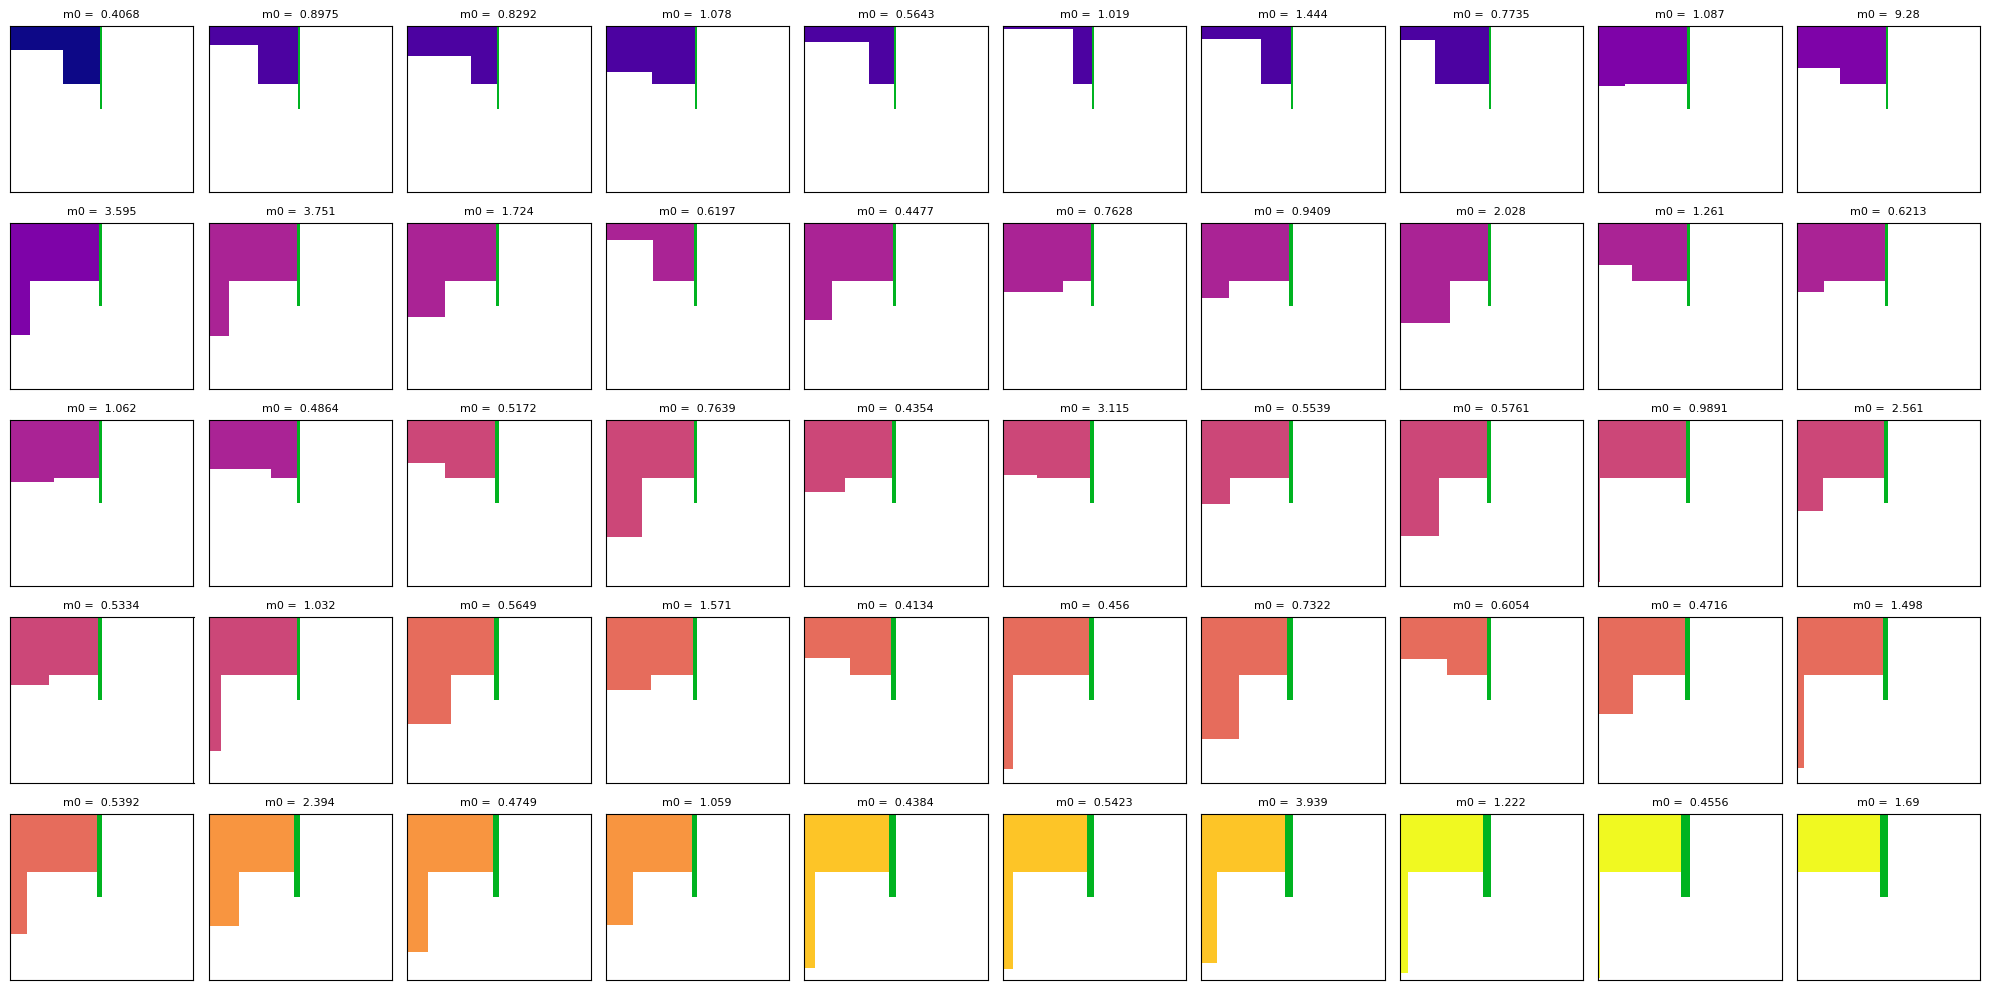

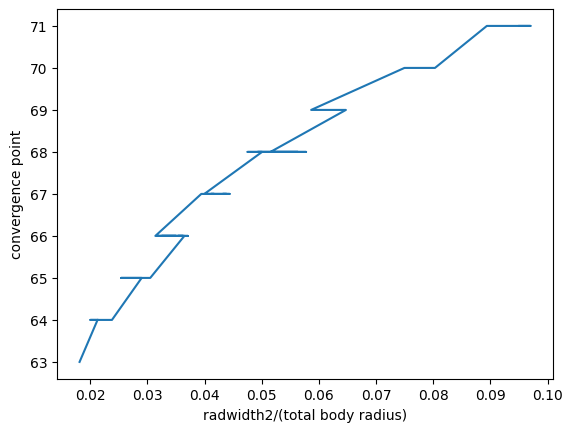

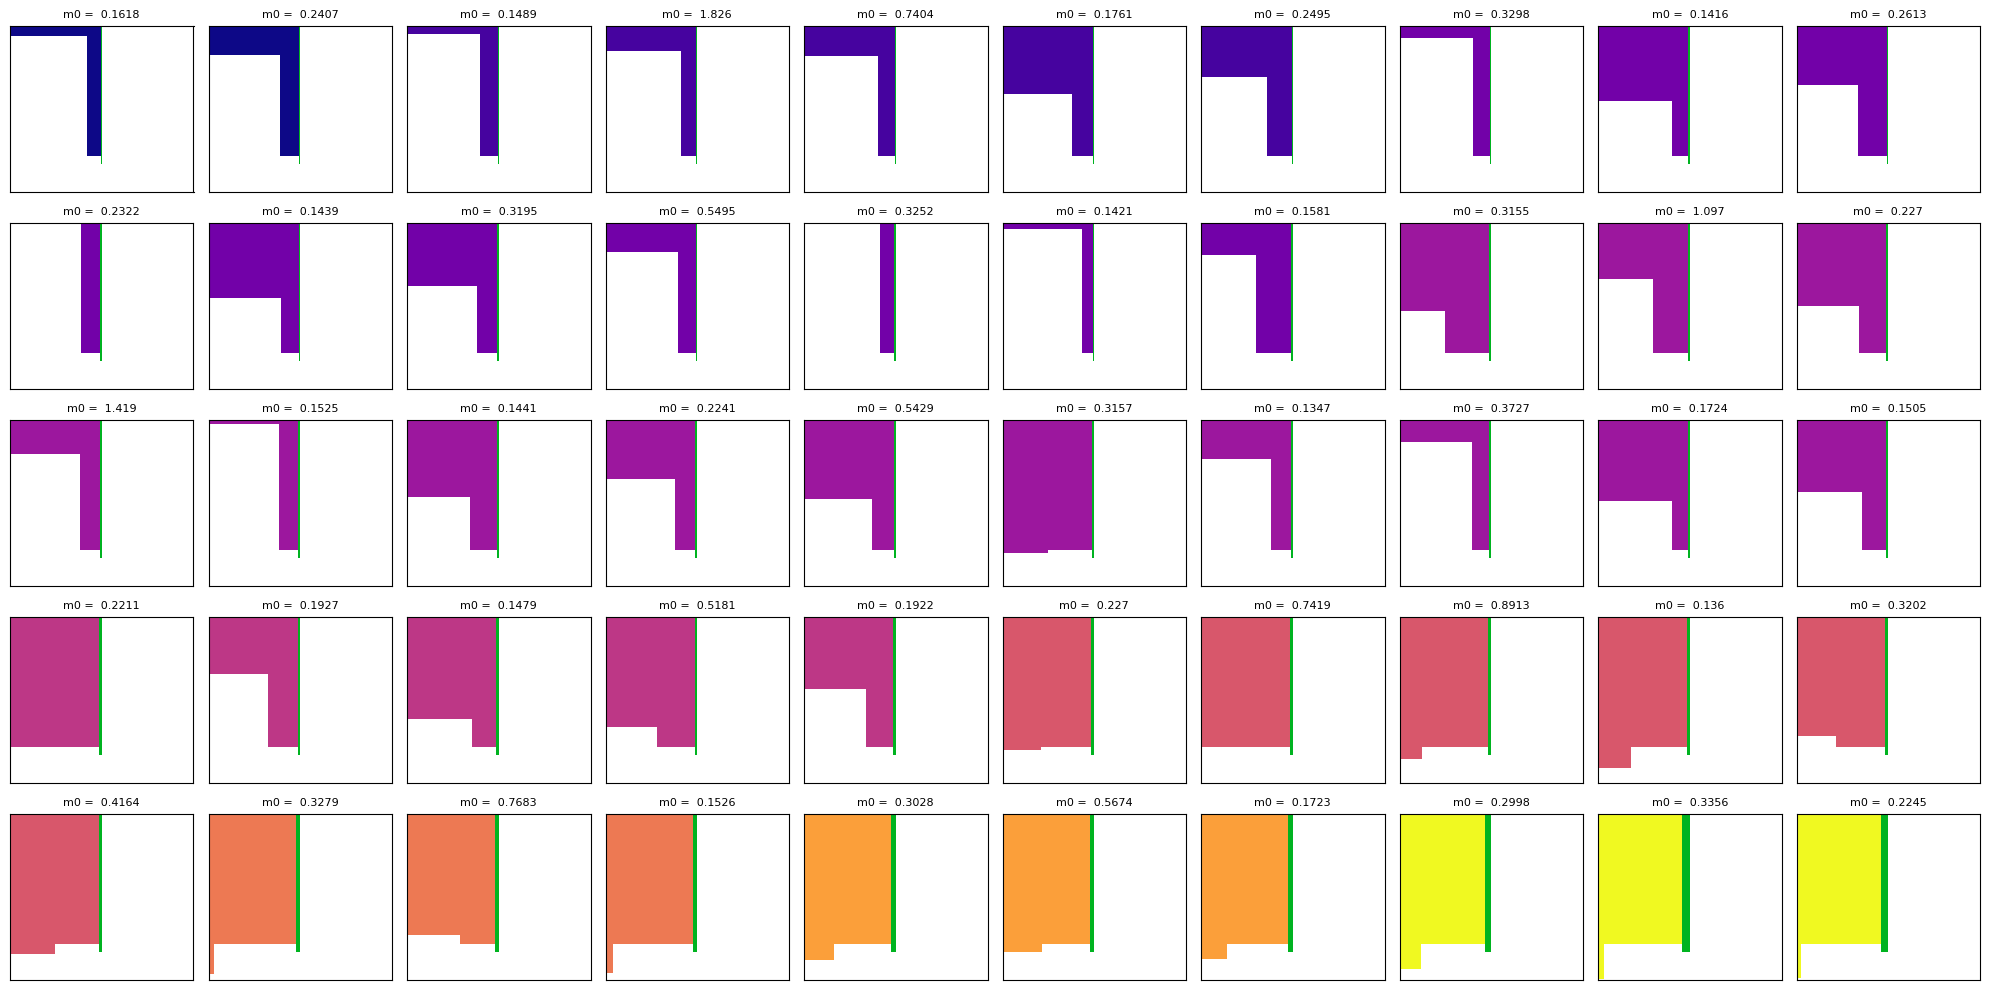

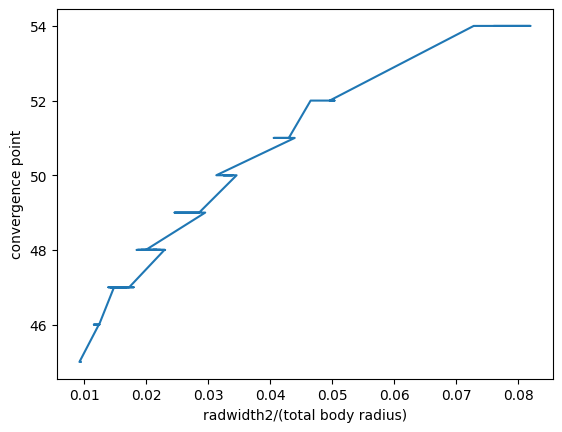

In [12]:
# Show geometric relation for convergence differences in wide histograms
for idx in wide_variation_cases:
  plot_varied_cases(fixed_prob_lsts, idx)